# DS 5007 - NLP Assignment 2: Neural NLP Pipeline (BBC Urdu)
**Student:** i25-8043  |  **Section:** DS-A  |  **Repository:** https://github.com/i258043-gif/i25-8043-NLP-Assignment2

Everything is implemented from scratch in PyTorch (no pretrained models, no Gensim, no HuggingFace, no `nn.Transformer` / `nn.MultiheadAttention` / `nn.TransformerEncoder`).

**Important notes**
* The Assignment-1 files were not available, so `cleaned.txt`, `raw.txt` and `Metadata.json` were rebuilt from two public BBC Urdu scrapes (`tools/build_corpus.py`): 504 articles, six BBC sections, 25,273 sentences.
* The assignment lists 11 POS tag names but calls them 12; we added `PART` (particles such as ہی، بھی، نہیں) as the 12th tag.
* The notebook displays results from the full runs stored in `results/`, `figures/`, `embeddings/` and `models/`. Training scripts (`src/part1.py`, `src/part2.py`, `src/part3.py`) regenerate everything (see README). The heavy training cells would take over an hour on a single CPU, so here they are loaded rather than retrained (`RETRAIN = False`).

In [1]:
import sys, os, json, inspect, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, ".")
import numpy as np, pandas as pd, torch
from IPython.display import Image, display
from src.common import *
RETRAIN = False
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)
show = lambda f: display(Image(filename=P("figures", f)))
print("torch", torch.__version__, "| numpy", np.__version__, "| seed", SEED, "| RETRAIN =", RETRAIN)
print("Repository:", "https://github.com/i258043-gif/i25-8043-NLP-Assignment2")

torch 2.15.0+cu132 | numpy 2.5.4 | seed 42 | RETRAIN = False
Repository: https://github.com/i258043-gif/i25-8043-NLP-Assignment2


In [2]:
sents = load_clean_sentences(); raw = load_raw_docs(); meta = load_meta()
toks = [t for s in sents for t in s]
print(f"documents={len(meta)}  sentences={len(sents):,}  tokens={len(toks):,}  distinct tokens={len(set(toks)):,}  raw documents={len(raw)}")
print(pd.Series([m['category_en'] for m in meta]).value_counts().to_string())
print("\nExample cleaned sentence:", " ".join(sents[100]))

documents=504  sentences=25,273  tokens=632,912  distinct tokens=21,800  raw documents=504
Pakistan             104
Region (Aas Paas)    100
Sports                93
Entertainment         84
World                 80
Science               43

Example cleaned sentence: وہ اسلام آباد کے ہسپتال میں داخل تھا


## Part 1: Word Embeddings (25 marks)
### 1.1 TF-IDF weighting

In [3]:
r1 = load_json("part1.json")
M = np.load(P("embeddings", "tfidf_matrix.npy"), mmap_mode="r")
print("tfidf_matrix.npy shape (vocabulary x documents):", M.shape, M.dtype, "| vocabulary = 10,000 most frequent tokens + <UNK>")
print("Formula: TF-IDF(w,d) = TF(w,d) * log(N / (1 + df(w))),  N =", r1["tfidf"]["n_docs"])
print("\nTop-10 most discriminative words per BBC section (mean TF-IDF):")
for c, w in r1["tfidf"]["top"].items(): print(f"  {c:20s}", " ".join(w))

tfidf_matrix.npy shape (vocabulary x documents): (10001, 504) float32 | vocabulary = 10,000 most frequent tokens + <UNK>
Formula: TF-IDF(w,d) = TF(w,d) * log(N / (1 + df(w))),  N = 504

Top-10 most discriminative words per BBC section (mean TF-IDF):
  Entertainment        فلم کپور فلموں عامر جیتیندر گانے لیاقت شادی کردار اجیت
  Pakistan             ٹیکس آگ پاکستان ایف بجٹ چائے اجلاس اسمبلی بلوچ مشرف
  Region (Aas Paas)    تیل پولیس انڈیا چین روس تائیوان موسے ایران طالبان جے
  Science              پلاسٹک جہاز جانور جانوروں پالتو مسک شابیگ آپ جنسی استعمال
  Sports               کرکٹ رنز میچ ٹیم ٹیسٹ اننگز پاکستان بابر گیند آسٹریلوی
  World                یوکرین عرب سعودی روس عدیفی روسی امریکی یورپی گوانتانامو امارات


### 1.2 PPMI co-occurrence matrix (window k = 5, symmetric)

In [4]:
pm = np.load(P("embeddings", "ppmi_matrix.npy"), mmap_mode="r")
nz = sum(int(np.count_nonzero(pm[i:i+500])) for i in range(0, pm.shape[0], 500))
print("ppmi_matrix.npy shape:", pm.shape, "| non-zero entries:", f"{nz:,}", f"({100*nz/pm.shape[0]**2:.2f}% dense)")
print("PPMI(w1,w2) = max(0, log2( P(w1,w2) / (P(w1) P(w2)) ))")
print("\nTop-5 nearest neighbours by cosine similarity (PPMI vectors, candidates with count >= 20):")
for w, nn in r1["ppmi_nn"].items(): print(f"  {w:10s}", "  ".join(f"{a}({b})" for a, b in nn))

ppmi_matrix.npy shape: (10001, 10001) | non-zero entries: 1,239,272 (1.24% dense)
PPMI(w1,w2) = max(0, log2( P(w1,w2) / (P(w1) P(w2)) ))

Top-5 nearest neighbours by cosine similarity (PPMI vectors, candidates with count >= 20):
  پاکستان    پاکستانی(0.22)  میں(0.219)  کے(0.215)  کرکٹ(0.209)  آسٹریلیا(0.205)
  انڈیا      میں(0.208)  کے(0.207)  انڈین(0.207)  ممالک(0.196)  پاکستان(0.173)
  حکومت      جانب(0.178)  کے(0.171)  وزیر(0.17)  پارٹی(0.165)  کی(0.162)
  کرکٹ       ٹیسٹ(0.281)  ون(0.234)  ڈے(0.232)  ٹیم(0.228)  کھیلنے(0.224)
  فلم        ریلیز(0.249)  فلمیں(0.248)  فلموں(0.223)  وڈ(0.218)  بالی(0.2)
  پولیس      افسر(0.233)  قتل(0.211)  سنتوش(0.209)  گرفتار(0.205)  بتایا(0.203)
  ٹیم        پاکستانی(0.286)  کپتان(0.231)  آسٹریلوی(0.23)  کرکٹ(0.228)  ٹیسٹ(0.213)
  عدالت      کورٹ(0.226)  رجوع(0.201)  درخواست(0.2)  دائر(0.196)  ہائیکورٹ(0.181)
  فوج        فوجیوں(0.184)  بھرتی(0.176)  پتھ(0.165)  جنرل(0.157)  اسرائیلی(0.154)
  صحت        عامہ(0.25)  مند(0.206)  ذہنی(0.176)  دماغی(0.

t-SNE of the 200 most frequent tokens, colour-coded by semantic category (counts per category): {'Politics / state': 7, 'Sports': 5, 'Geography / places': 8, 'Entertainment / media': 4, 'Society / economy': 4, 'Function words': 114, 'Other': 58}


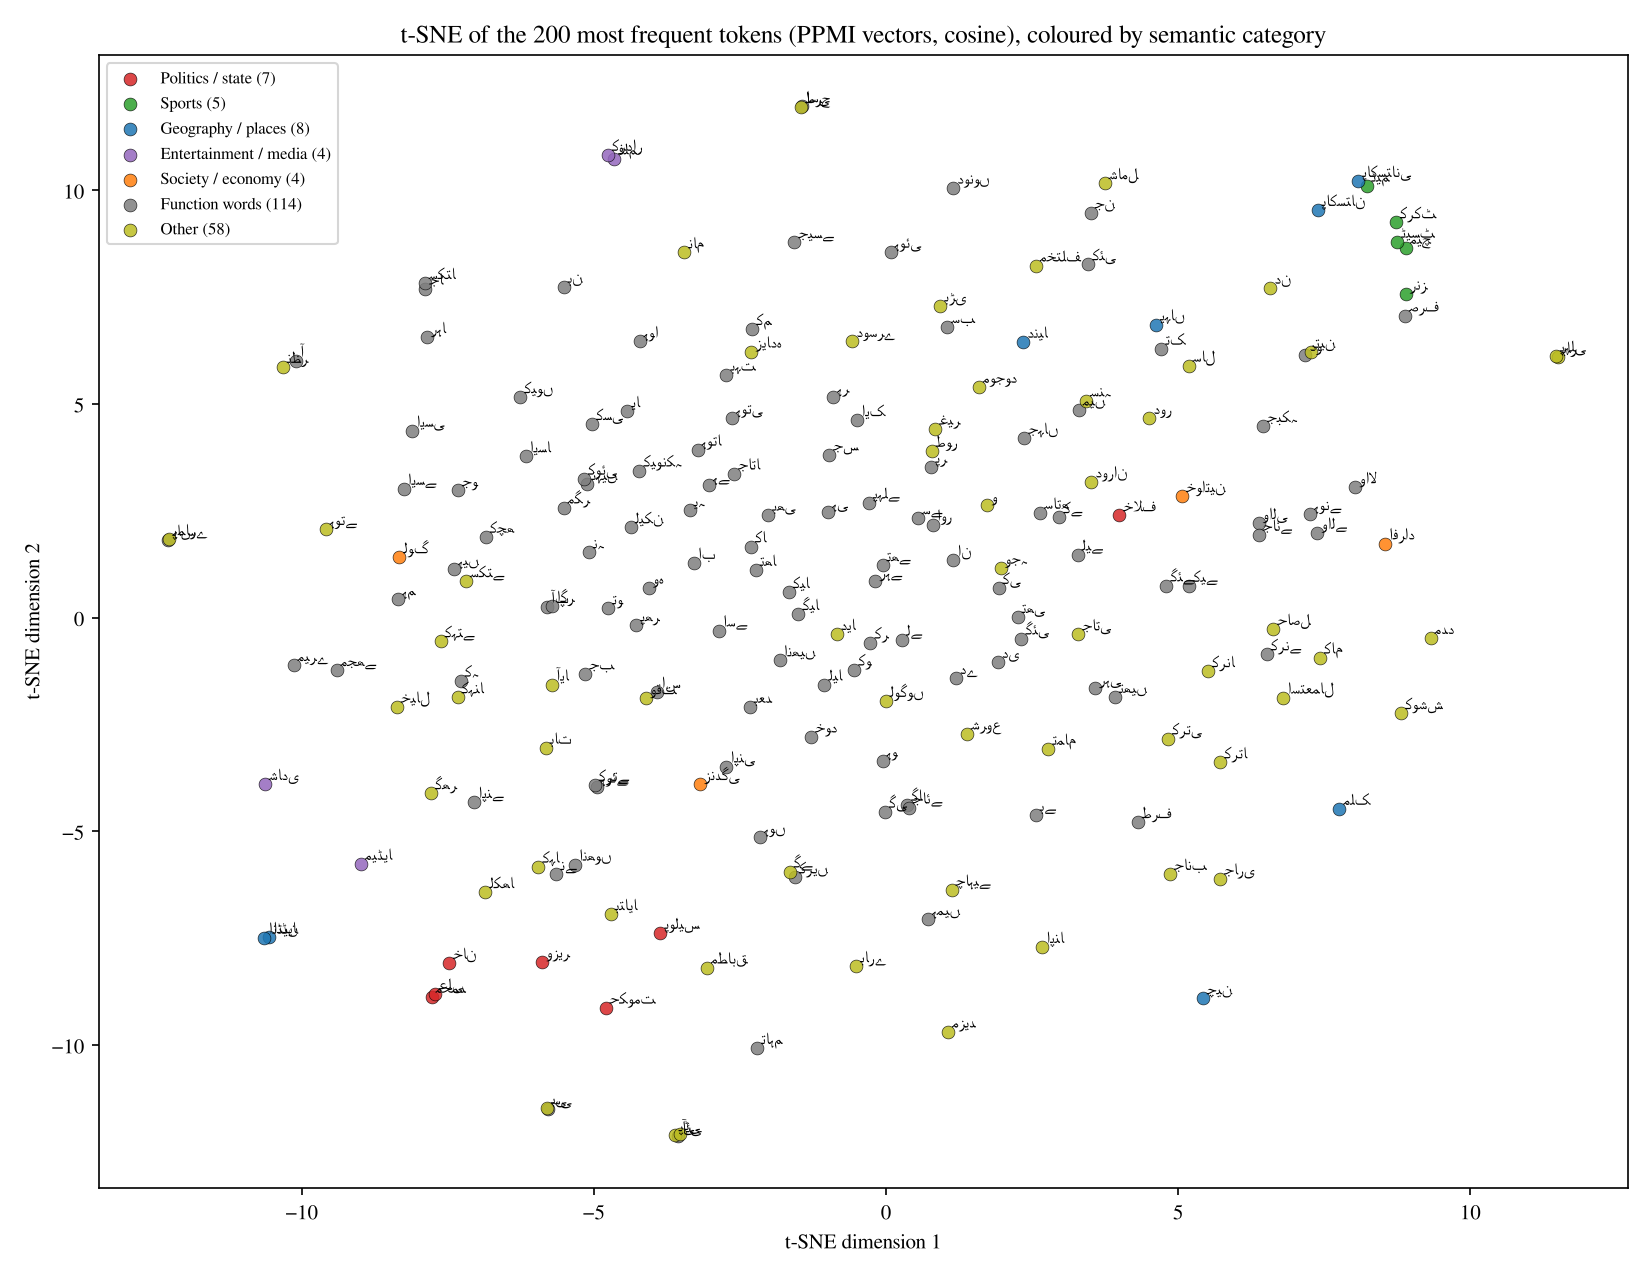

In [5]:
print("t-SNE of the 200 most frequent tokens, colour-coded by semantic category (counts per category):", r1["tsne_counts"])
show("tsne_ppmi_top200.png")

### 2.1 Skip-gram Word2Vec with negative sampling

In [6]:
from src import part1
print(inspect.getsource(part1.SkipGram)); print(inspect.getsource(part1.make_pairs))

class SkipGram(nn.Module):
    """Centre matrix V and context matrix U, both |V| x d."""
    def __init__(self, V, d):
        super().__init__()
        self.V = nn.Embedding(V, d); self.U = nn.Embedding(V, d)
        nn.init.uniform_(self.V.weight, -0.5 / d, 0.5 / d); nn.init.uniform_(self.U.weight, -0.5 / d, 0.5 / d)

    def forward(self, c, o, neg):                      # c:[B] o:[B] neg:[B,K]
        vc = self.V(c)                                 # [B,d]
        pos = F.logsigmoid((self.U(o) * vc).sum(-1))   # log sigma(u_o . v_c)
        ng = F.logsigmoid(-torch.bmm(self.U(neg), vc.unsqueeze(2)).squeeze(2)).sum(-1)   # sum_k log sigma(-u_w . v_c)
        return -(pos + ng).mean()

    def final(self):                                   # averaged embeddings 1/2 (V+U)
        return 0.5 * (self.V.weight + self.U.weight).detach().cpu().numpy()

def make_pairs(tok, sid, keep, rng, k=WINDOW):
    """tok/sid: flat arrays of token ids and sentence ids. Frequent-word subsampling then (c

In [7]:
from collections import Counter
cnt = Counter(toks); stoi = json.load(open(P("embeddings", "word2idx.json"), encoding="utf8"))
freq = np.array([cnt.get(w, 0) for w in stoi], dtype=float); noise = freq ** 0.75; noise /= noise.sum()
print("Vocabulary size |V| =", len(stoi), "(10,000 + <UNK>)")
print("Noise distribution P(w) ~ f(w)^(3/4): most likely noise words:")
iw = {i: w for w, i in stoi.items()}
for i in np.argsort(-noise)[:8]: print(f"  {iw[i]:8s} unigram={freq[i]/freq.sum():.4f}  noise P={noise[i]:.4f}")
print("\nHyper-parameters:", r1["config"], "| K = 10 negative samples per positive pair")
print("Skip-gram pairs per epoch ~ 2.32 million (after frequent-word subsampling, t=1e-4)")

Vocabulary size |V| = 10001 (10,000 + <UNK>)
Noise distribution P(w) ~ f(w)^(3/4): most likely noise words:
  کے       unigram=0.0413  noise P=0.0141
  میں      unigram=0.0338  noise P=0.0121
  کی       unigram=0.0302  noise P=0.0111
  ہے       unigram=0.0227  noise P=0.0090
  سے       unigram=0.0201  noise P=0.0082
  اور      unigram=0.0189  noise P=0.0078
  کہ       unigram=0.0169  noise P=0.0072
  کا       unigram=0.0162  noise P=0.0070

Hyper-parameters: {'window': 5, 'K': 10, 'epochs': 25, 'batch': 1024, 'lr': 0.001, 'd': 100, 'vocab': 10001, 'tokens': 632912, 'subsample_t': 0.0001} | K = 10 negative samples per positive pair
Skip-gram pairs per epoch ~ 2.32 million (after frequent-word subsampling, t=1e-4)


Training loss for C3 (skip-gram on cleaned.txt, d=100), per epoch:
  [C3] epoch 1/25 pairs=2,319,136 loss=3.5735 (38s)
  [C3] epoch 2/25 pairs=2,323,572 loss=3.2037 (123s)
  [C3] epoch 2/25 pairs=2,323,572 loss=3.2039 (85s)
  [C3] epoch 3/25 pairs=2,316,492 loss=3.0408 (201s)
  [C3] epoch 3/25 pairs=2,316,492 loss=3.0408 (163s)
  [C3] epoch 4/25 pairs=2,321,288 loss=2.9341 (196s)
  [C3] epoch 5/25 pairs=2,319,248 loss=2.8551 (229s)
  [C3] epoch 6/25 pairs=2,321,886 loss=2.7923 (33s)
  [C3] epoch 7/25 pairs=2,319,846 loss=2.7395 (61s)
  [C3] epoch 8/25 pairs=2,322,748 loss=2.6929 (92s)
  [C3] epoch 9/25 pairs=2,322,088 loss=2.6525 (120s)
  [C3] epoch 10/25 pairs=2,317,040 loss=2.6185 (149s)
  [C3] epoch 11/25 pairs=2,322,222 loss=2.5929 (181s)
  [C3] epoch 12/25 pairs=2,319,508 loss=2.5663 (211s)
  [C3] epoch 13/25 pairs=2,320,224 loss=2.5498 (36s)
  [C3] epoch 14/25 pairs=2,319,504 loss=2.5320 (67s)
  [C3] epoch 15/25 pairs=2,326,424 loss=2.5197 (97s)
  [C3] epoch 16/25 pairs=2,318,604

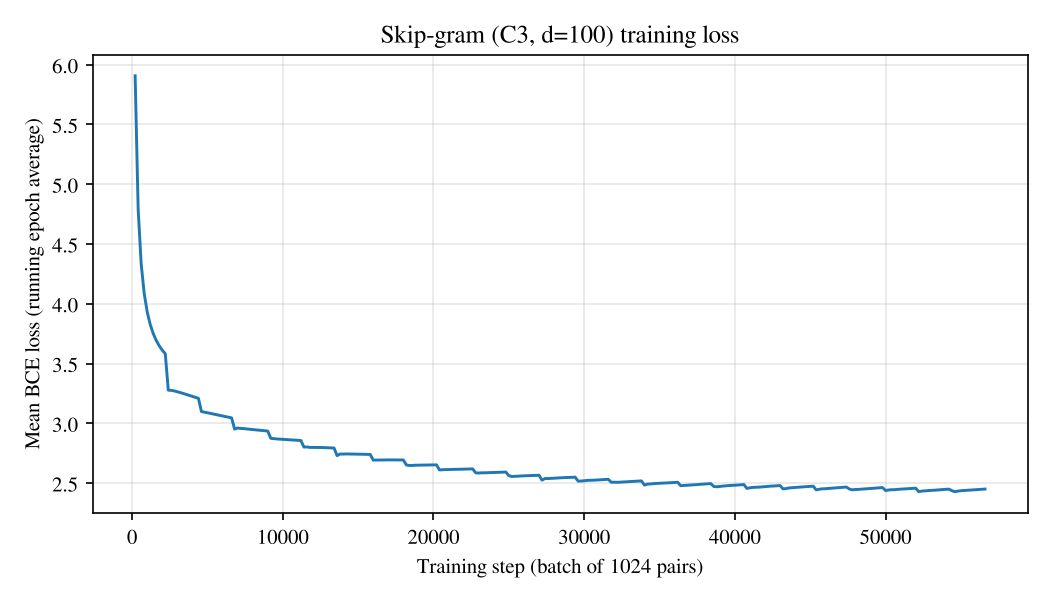

embeddings_w2v.npy = 1/2 (V + U): (10001, 100)


In [8]:
import re
log = open(P("results", "part1_log.txt"), encoding="utf8").read().splitlines()
print("Training loss for C3 (skip-gram on cleaned.txt, d=100), per epoch:")
for l in [l for l in log if re.match(r"\[C3\] epoch \d+/25", l)]: print(" ", l)
h = load_json("p1_C3.json")["hist"]
print("\nLoss at regular intervals (every 1,000 steps):", [(s, round(v, 3)) for s, v in h if s % 1000 == 0][:12])
show("w2v_loss_curve.png")
E3 = np.load(P("embeddings", "embeddings_w2v.npy")); print("embeddings_w2v.npy = 1/2 (V + U):", E3.shape)

### 2.2 Evaluation

In [9]:
print("Top-10 nearest neighbours (cosine, C3 embeddings; candidates with corpus count >= 20):\n")
for k, v in r1["nn10"].items(): print(f"{k:9s}", "  ".join(a for a, _ in v))

Top-10 nearest neighbours (cosine, C3 embeddings; candidates with corpus count >= 20):

Pakistan  کرکٹ  ٹیسٹ  سیریز  لیگ  پاکستانی  آسٹریلیا  ٹوئنٹی  ون  ٹیم  وفاقی
Hukumat   جماعتوں  وفاقی  طالبان  سیاسی  جانب  وزیر  موجودہ  منظوری  سبسڈی  مذاکرات
Adalat    مقدمے  دائر  کورٹ  سماعت  فیصلہ  عدالتوں  مجسٹریٹ  جج  رجوع  مہدی
Maeeshat  اقتصادی  ملکی  بڑھانے  انحصار  کرپٹو  شرائط  تیل  معاشی  وسائل  پروگرام
Fauj      تعینات  افواج  فوجیوں  پتھ  افسران  جنرل  اگنی  میجر  بھرتی  نوجوانوں
Sehat     مند  دماغی  ذہنی  طرز  سہولیات  بیماری  خطرات  بھال  حیدرآباد  گزارنے
Taleem    سکولوں  سکول  بچوں  باقاعدہ  حاصل  سول  ملازمت  حجاب  ٹرسٹ  سنید
Aabadi    فیصد  تباہی  ہندوستانی  چین  خیر  شرح  1  پہنچ  آمدنی  کھپت


In [10]:
df = pd.DataFrame([{"analogy a : b :: c : ?": f"{t['a']} : {t['b']} :: {t['c']} : ?", "gold": t["gold"], "top-3": " | ".join(t["top3"]),
                    "top-1 correct": t["top1_correct"], "gold in top-3": t["top3_correct"]} for t in r1["analogies"]])
print(df.to_string(index=False))
print(f"\nCorrect at top-1: {int(df['top-1 correct'].sum())}/10   |   gold within top-3 candidates: {int(df['gold in top-3'].sum())}/10 (requirement: at least 5 correct)")

         analogy a : b :: c : ?     gold                  top-3  top-1 correct  gold in top-3
پاکستان : پاکستانی :: انڈیا : ?    انڈین     انڈین | برانڈ | دت           True           True
امریکہ : امریکی :: آسٹریلیا : ? آسٹریلوی   ٹیسٹ | آسٹریلوی | آل          False           True
          چین : چینی :: روس : ?     روسی یوکرین | روسی | فوجیوں          False           True
       بیٹا : بیٹی :: بھائی : ?      بہن    بہن | پارٹی | جعفری           True           True
       پہلی : پہلا :: دوسری : ?    دوسرا   جانب | دوسرا | تیسرا          False           True
           بڑی : بڑا :: نئی : ?      نیا        مقصد | نئے | سا          False          False
         مرد : عورت :: شوہر : ?     بیوی     شادی | ماں | عتیقہ          False          False
     لاہور : پنجاب :: کراچی : ?     سندھ    صوبہ | لاپتہ | بلوچ          False          False
        جاتا : جاتی :: کرتا : ?     کرتی     ہوتی | ہماری | تھی          False          False
        مردوں : مرد :: بچوں : ?      بچہ  بچے | والدین | دوس

In [11]:
print("""Assessment (does the embedding space capture meaningful semantics?)
The embeddings capture topical and some morphological relations: the neighbours of عدالت (court) are legal terms (مقدمے, دائر, کورٹ, سماعت, فیصلہ), those of پاکستان are cricket
terms reflecting the news domain, and انڈیا : انڈین follows the nationality pattern. They are noisy, however: with only ~633k training tokens, relational analogies such as
city -> province fail and function words or rare names intrude, so the vectors encode topical association better than precise relations. We kept the 10 analogies fixed
before evaluating and did not tune them to the results.""")

Assessment (does the embedding space capture meaningful semantics?)
The embeddings capture topical and some morphological relations: the neighbours of عدالت (court) are legal terms (مقدمے, دائر, کورٹ, سماعت, فیصلہ), those of پاکستان are cricket
terms reflecting the news domain, and انڈیا : انڈین follows the nationality pattern. They are noisy, however: with only ~633k training tokens, relational analogies such as
city -> province fail and function words or rare names intrude, so the vectors encode topical association better than precise relations. We kept the 10 analogies fixed
before evaluating and did not tune them to the results.


In [12]:
rows = []
for k, v in r1["conditions"].items(): rows.append({"Condition": k, "dim": v["dim"], "MRR (20 labelled pairs)": round(v["mrr"], 4), "pairs missing from vocab": v["missing"]})
print(pd.DataFrame(rows).to_string(index=False))
print("\nTop-5 nearest neighbours of 5 query words per condition:")
for k, v in r1["conditions"].items():
    print("\n" + k)
    for w, nn in v["nn5"].items(): print(f"   {w:8s}", "  ".join(nn))
c2 = r1["conditions"]["C2 Skip-gram raw (d=100)"]; print("\nRaw vocabulary entries containing attached punctuation:", c2["raw_vocab_with_punct"], "of", c2["raw_vocab"] - 1)

                   Condition             dim  MRR (20 labelled pairs)  pairs missing from vocab
            C1 PPMI baseline 10,001 (sparse)                   0.2226                         0
    C2 Skip-gram raw (d=100)             100                   0.1318                         0
C3 Skip-gram cleaned (d=100)             100                   0.1131                         0
C4 Skip-gram cleaned (d=200)             200                   0.1140                         0

Top-5 nearest neighbours of 5 query words per condition:

C1 PPMI baseline
   پاکستان  پاکستانی  میں  کے  کرکٹ  آسٹریلیا
   حکومت    جانب  کے  وزیر  پارٹی  کی
   عدالت    کورٹ  رجوع  درخواست  دائر  سپریم
   فوج      فوجیوں  بھرتی  پتھ  جنرل  اسرائیلی
   صحت      مند  ذہنی  دماغی  طبی  خوراک

C2 Skip-gram raw (d=100)
   پاکستان  ٹیسٹ  کرکٹ  پیس  ٹیم  پاکستانی
   حکومت    جماعتوں  اتحادی  سیاسی  وزیر  طالبان
   عدالت    رجوع  دائر  مقدمے  کورٹ  جج
   فوج      بھرتی  میجر  جنرل  پتھ  افسران
   صحت      ذہنی  مند  بیم

In [13]:
print("""Discussion of the four conditions
* C1 PPMI obtained the highest MRR (0.223), followed by C2 raw skip-gram (0.132), C4 d=200 (0.114) and C3 cleaned skip-gram (0.113). On this small corpus (~633k tokens) the count-based
  PPMI vectors, which use every co-occurrence exactly, are a stronger baseline than skip-gram trained for 25 epochs; skip-gram with negative sampling normally needs far more data.
* Cleaning did not improve MRR: C2 (raw) is slightly better than C3 (cleaned), although with only 20 pairs the difference is within noise. Qualitatively the five query words give
  similar political/legal neighbours in C2, C3 and C4. Raw text keeps 1,133 punctuation-attached variants in its vocabulary but also keeps information (e.g. sentence-final marks) that cleaning removes.
* Doubling the dimension (C4, d=200) did not help (0.114 vs 0.113): the corpus is the bottleneck, not the capacity of the vectors.
* Overall, PPMI yields the best embeddings by MRR here; among the neural models C2 and C3/C4 are close. C3 is used downstream (Part 2) as required.""")

Discussion of the four conditions
* C1 PPMI obtained the highest MRR (0.223), followed by C2 raw skip-gram (0.132), C4 d=200 (0.114) and C3 cleaned skip-gram (0.113). On this small corpus (~633k tokens) the count-based
  PPMI vectors, which use every co-occurrence exactly, are a stronger baseline than skip-gram trained for 25 epochs; skip-gram with negative sampling normally needs far more data.
* Cleaning did not improve MRR: C2 (raw) is slightly better than C3 (cleaned), although with only 20 pairs the difference is within noise. Qualitatively the five query words give
  similar political/legal neighbours in C2, C3 and C4. Raw text keeps 1,133 punctuation-attached variants in its vocabulary but also keeps information (e.g. sentence-final marks) that cleaning removes.
* Doubling the dimension (C4, d=200) did not help (0.114 vs 0.113): the corpus is the bottleneck, not the capacity of the vectors.
* Overall, PPMI yields the best embeddings by MRR here; among the neural models C2 and C3

## Part 2: Sequence Labeling - POS Tagging & NER (25 marks)
### 3. Dataset preparation

In [14]:
from src import lexicons as L
d2 = load_json("part2_data.json")
print("Lexicon entries (hand-crafted, per category):", d2["lexicon_sizes"])
print("Gazetteer entries:", d2["gazetteer_sizes"], "(requirement: >=50 persons, >=50 locations, >=30 organisations; >=200 per major open-class category)")
print("Tag set (12):", L.TAGS); print("NER tags:", L.NER_TAGS)
spl = load_json("part2_data.json")
print("\nSplit sizes:", spl["sizes"], "| topic distribution:", spl["topic_dist"])
print("Sentences:", sum(spl["sizes"].values()), "| tokens:", spl["n_tokens"], "| entity counts:", spl["entity_counts"])

Lexicon entries (hand-crafted, per category): {'NOUN': 845, 'VERB': 217, 'ADJ': 450, 'ADV': 206, 'PRON': 57, 'DET': 44, 'CONJ': 28, 'POST': 56, 'PART': 11, 'NUM': 73}
Gazetteer entries: {'PER': 147, 'LOC': 113, 'ORG': 98, 'MISC': 64} (requirement: >=50 persons, >=50 locations, >=30 organisations; >=200 per major open-class category)
Tag set (12): ['NOUN', 'VERB', 'ADJ', 'ADV', 'PRON', 'DET', 'CONJ', 'POST', 'NUM', 'PUNC', 'PART', 'UNK']
NER tags: ['O', 'B-PER', 'I-PER', 'B-LOC', 'I-LOC', 'B-ORG', 'I-ORG', 'B-MISC', 'I-MISC']

Split sizes: {'train': 350, 'val': 74, 'test': 76} | topic distribution: {'train': {'Pakistan': 140, 'Entertainment': 105, 'Sports': 105}, 'val': {'Pakistan': 30, 'Entertainment': 22, 'Sports': 22}, 'test': {'Entertainment': 23, 'Sports': 23, 'Pakistan': 30}}
Sentences: 500 | tokens: 10250 | entity counts: {'LOC': 121, 'PER': 38, 'MISC': 76, 'ORG': 18}


In [15]:
split = json.load(open(P("data", "split_annotated.json"), encoding="utf8"))
print("POS label distribution (token counts):"); print(pd.DataFrame(d2["pos_dist"]).fillna(0).astype(int).reindex(L.TAGS).fillna(0).astype(int).to_string())
print("\nNER label distribution (token counts):"); print(pd.DataFrame(d2["ner_dist"]).fillna(0).astype(int).reindex(L.NER_TAGS).to_string())
print("\nNote: cleaned.txt contains no punctuation, so PUNC has zero support (it stays in the 12-tag confusion matrix).")
s = next(d for d in split["train"] if any(t != "O" for t in d["ner"]))
print("\nExample annotated sentence:"); print(pd.DataFrame({"token": s["tokens"], "POS": s["pos"], "NER": s["ner"]}).T.to_string(header=False))

POS label distribution (token counts):
      train  val  test
NOUN   2095  513   496
VERB   1427  319   338
ADJ     333   89    86
ADV     235   58    56
PRON    441   81    94
DET     299   51    55
CONJ    344   85    78
POST   1454  335   325
NUM     135   38    34
PUNC      0    0     0
PART    214   54    45
UNK      30    6     7

NER label distribution (token counts):
        train   val  test
O        6785  1556  1548
B-PER      22     6    10
I-PER      24     7    11
B-LOC      78    28    15
I-LOC       9     5     2
B-ORG      12     3     3
I-ORG      16     2     6
B-MISC     44    17    15
I-MISC     17     5     4

Note: cleaned.txt contains no punctuation, so PUNC has zero support (it stays in the 12-tag confusion matrix).

Example annotated sentence:
token  حالیہ  دنوں   میں  وفاقی  حکومت    کی  جانب    سے  پاکستان    کا   بجٹ  متعارف  کراتے  ہوئے  تقریبا   14  نکات    پر  خاص   زور   دیا   گیا   تھا
POS      ADJ  NOUN  POST    ADJ   NOUN  POST  POST  POST     NOUN  P

In [16]:
for f in ("pos_train", "pos_val", "pos_test", "ner_train", "ner_val", "ner_test"):
    n = open(P("data", f + ".conll"), encoding="utf8").read().count("\n\n"); print(f"data/{f}.conll : {n} sentences")
print("\nCaveat: labels are silver (rule-based tagger + gazetteer), not human-checked.")

data/pos_train.conll : 350 sentences
data/pos_val.conll : 74 sentences
data/pos_test.conll : 76 sentences
data/ner_train.conll : 350 sentences
data/ner_val.conll : 74 sentences
data/ner_test.conll : 76 sentences

Caveat: labels are silver (rule-based tagger + gazetteer), not human-checked.


### 4. BiLSTM sequence labeller (2 layers, bidirectional, dropout 0.5, CRF/Viterbi for NER)

In [17]:
from src import seqlabel
print(inspect.getsource(seqlabel.CRF)); print(inspect.getsource(seqlabel.BiLSTMTagger))

class CRF(nn.Module):
    """Linear-chain CRF with a learnable tag-transition matrix (plus start/end scores); Viterbi decoding."""
    def __init__(self, n):
        super().__init__()
        self.n = n
        self.trans = nn.Parameter(torch.randn(n, n) * 0.01)       # trans[i, j] = score of moving from tag i to tag j
        self.start = nn.Parameter(torch.zeros(n)); self.end = nn.Parameter(torch.zeros(n))

    def gold_score(self, em, tags, mask):
        B, T, _ = em.shape; m = mask.float()
        sc = self.start[tags[:, 0]] + em[:, 0].gather(1, tags[:, :1]).squeeze(1)
        for t in range(1, T):
            step = self.trans[tags[:, t - 1], tags[:, t]] + em[:, t].gather(1, tags[:, t:t + 1]).squeeze(1)
            sc = sc + step * m[:, t]
        last = tags.gather(1, (mask.sum(1) - 1).unsqueeze(1)).squeeze(1)
        return sc + self.end[last]

    def log_partition(self, em, mask):
        B, T, n = em.shape
        alpha = self.start + em[:, 0]
        for t in range(1, T):


In [18]:
sc = seqlabel.crf_selfcheck()
print("CRF verification against brute-force enumeration of all tag paths (2 sequences, one padded):")
for b, v in sc.items(): print(f"  seq {b}: log Z (CRF forward algorithm) = {v['logZ_crf']:.5f} | brute force = {v['logZ_brute']:.5f} | Viterbi path = {v['viterbi']} | brute-force best = {v['brute']}")
print("\nPadding handling: POS uses cross_entropy(ignore_index=-100) and sequences are packed (pack_padded_sequence); the CRF masks padded steps in both the partition function and the gold score.")

CRF verification against brute-force enumeration of all tag paths (2 sequences, one padded):
  seq 0: log Z (CRF forward algorithm) = 8.87137 | brute force = 8.87137 | Viterbi path = (2, 0, 2, 0) | brute-force best = (2, 0, 2, 0)
  seq 1: log Z (CRF forward algorithm) = 2.61690 | brute force = 2.61690 | Viterbi path = (1, 1, 1) | brute-force best = (1, 1, 1)

Padding handling: POS uses cross_entropy(ignore_index=-100) and sequences are packed (pack_padded_sequence); the CRF masks padded steps in both the partition function and the gold score.


In [19]:
a2 = load_json("part2_analysis.json"); T = a2["table"]
f = lambda d, k: f"{d[k]['mean']:.3f} +- {d[k]['std']:.3f}"
rows = [{"Task": "POS (macro-F1)", "Mode": m, "Validation F1": f(T[n], "val_f1"), "Test F1": f(T[n], "test_f1")} for m, n in (("Frozen w2v (C3)", "pos_frozen"), ("Fine-tuned w2v (C3)", "pos_ft"))]
rows += [{"Task": "NER (entity F1)", "Mode": m, "Validation F1": f(T[n], "val_f1"), "Test F1": f(T[n], "test_f1")} for m, n in (("Frozen w2v (C3)", "ner_frozen"), ("Fine-tuned w2v (C3)", "ner_ft"))]
print("Frozen vs fine-tuned embeddings (mean +- std over seeds 42, 43):"); print(pd.DataFrame(rows).to_string(index=False))
print("\nFine-tuning clearly helps (POS +0.25, NER +0.25 validation F1): the frozen C3 vectors were trained on a small corpus and do not encode tag/entity information; the fine-tuned model is used for all later experiments.")

Frozen vs fine-tuned embeddings (mean +- std over seeds 42, 43):
           Task                Mode  Validation F1        Test F1
 POS (macro-F1)     Frozen w2v (C3) 0.576 +- 0.031 0.563 +- 0.022
 POS (macro-F1) Fine-tuned w2v (C3) 0.825 +- 0.006 0.822 +- 0.009
NER (entity F1)     Frozen w2v (C3) 0.493 +- 0.040 0.394 +- 0.027
NER (entity F1) Fine-tuned w2v (C3) 0.745 +- 0.005 0.627 +- 0.030

Fine-tuning clearly helps (POS +0.25, NER +0.25 validation F1): the frozen C3 vectors were trained on a small corpus and do not encode tag/entity information; the fine-tuned model is used for all later experiments.


Training setup: Adam (lr 1e-3, weight decay 1e-4), early stopping on validation F1, patience 5 (counted after a 20-epoch warm-up for NER, because the CRF model sits at F1 = 0 for its first epochs).
Best epochs (seed 42): {'pos_ft': 25, 'ner_ft': 25}


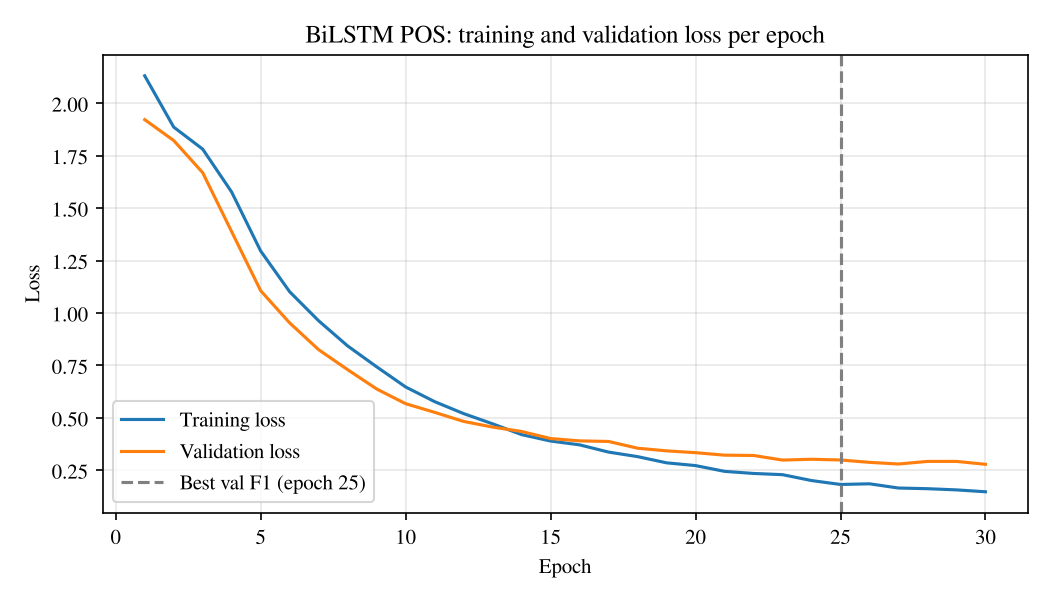

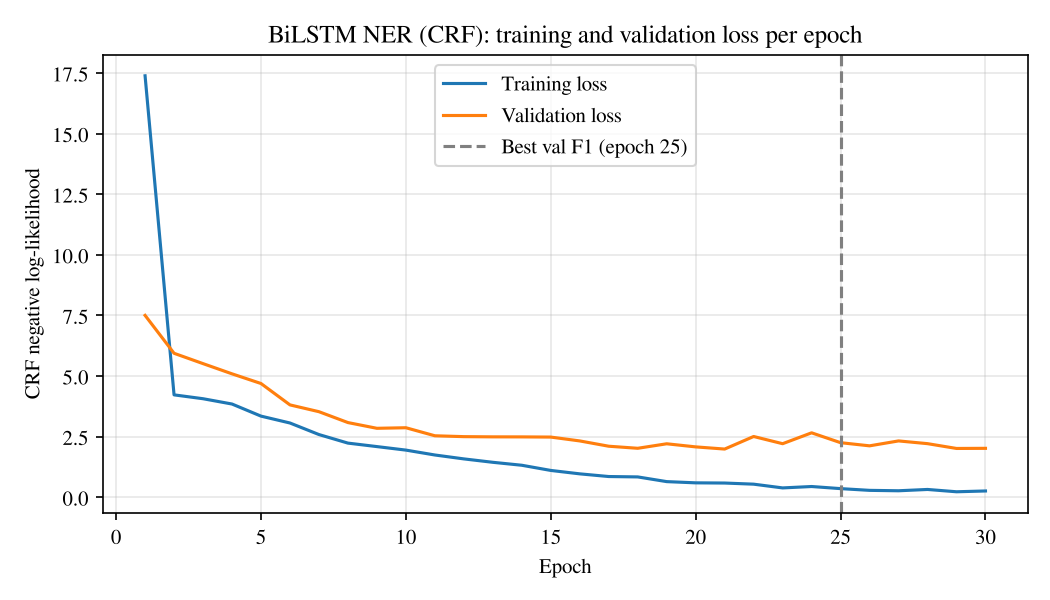

In [20]:
print("Training setup: Adam (lr 1e-3, weight decay 1e-4), early stopping on validation F1, patience 5 (counted after a 20-epoch warm-up for NER, because the CRF model sits at F1 = 0 for its first epochs).")
print("Best epochs (seed 42):", a2["best_epoch"])
show("pos_ft_loss_curves.png"); show("ner_ft_loss_curves.png")

### 5.1 POS tagging evaluation

Test token accuracy: 0.933 +- 0.004   macro-F1 (tags present in test): 0.822 +- 0.009   (mean over 2 seeds; seed 42: acc 0.929, macro-F1 0.812)

Frozen vs fine-tuned summary table (test):
      Mode       Accuracy       Macro-F1
    Frozen 0.751 +- 0.011 0.563 +- 0.022
Fine-tuned 0.933 +- 0.004 0.822 +- 0.009


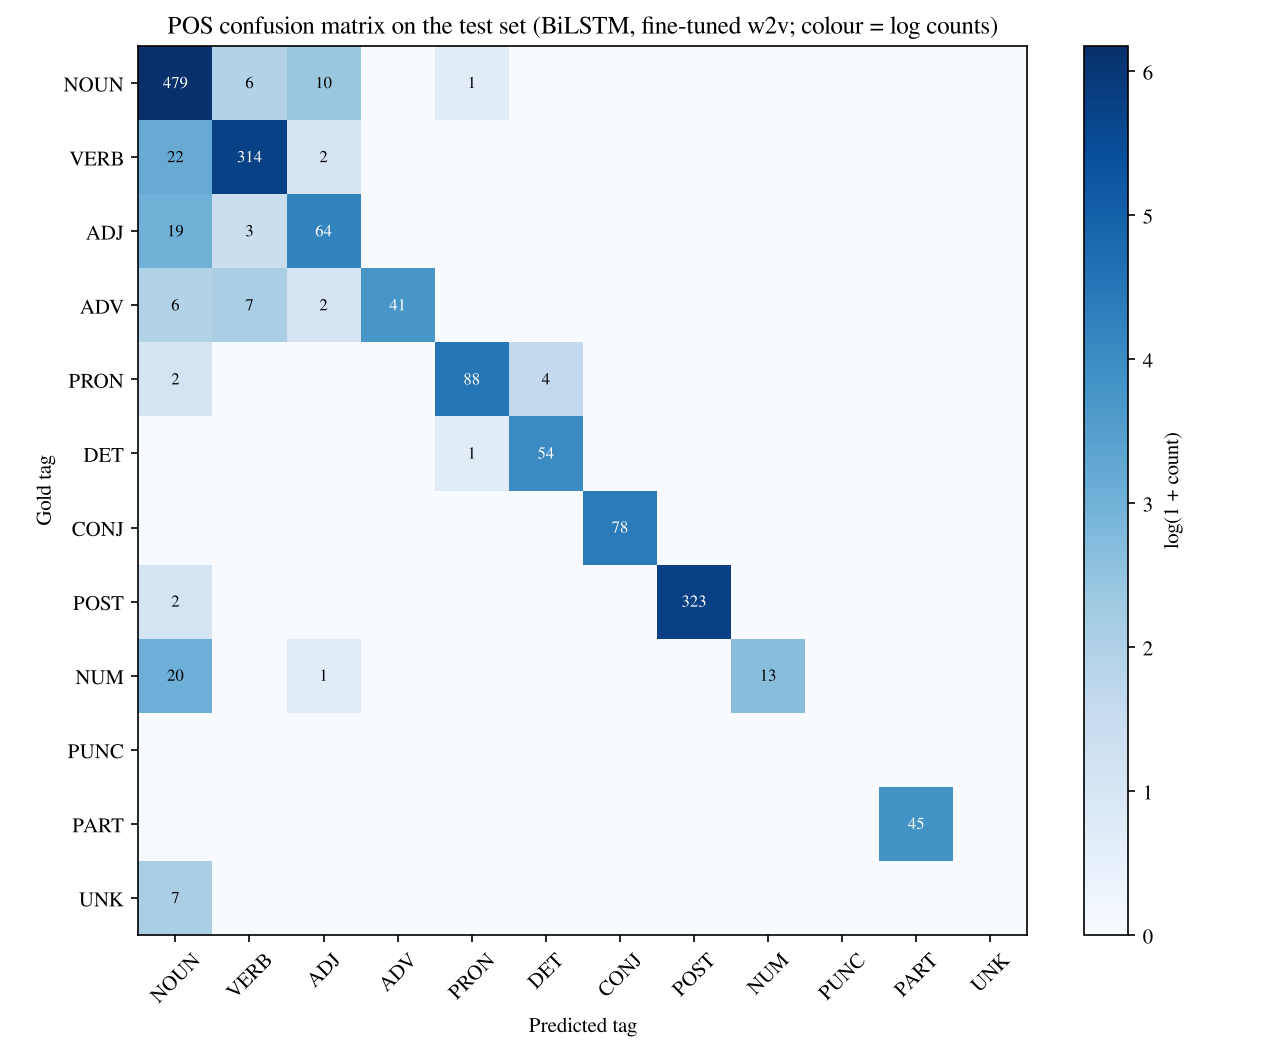

In [21]:
t = T["pos_ft"]; print(f"Test token accuracy: {t['test_acc']['mean']:.3f} +- {t['test_acc']['std']:.3f}   macro-F1 (tags present in test): {t['test_f1']['mean']:.3f} +- {t['test_f1']['std']:.3f}   (mean over 2 seeds; seed 42: acc {a2['pos']['test']['acc']:.3f}, macro-F1 {a2['pos']['test']['macro_f1']:.3f})")
print("\nFrozen vs fine-tuned summary table (test):")
print(pd.DataFrame([{"Mode": m, "Accuracy": f(T[n], "test_acc"), "Macro-F1": f(T[n], "test_f1")} for m, n in (("Frozen", "pos_frozen"), ("Fine-tuned", "pos_ft"))]).to_string(index=False))
show("pos_confusion_matrix.png")

In [22]:
print("Three most confused tag pairs (test, seed 42) with example sentences:\n")
for pair, v in a2["pos"]["top_pairs"].items():
    print(f"== {pair}: {v['count']} confusions")
    for e in v["examples"]: print(f"   token '{e['token']}' gold={e['gold']} predicted={e['pred']} | {e['sentence']}")
print("\nAnalysis: ADJ/NOUN and NOUN/VERB confusions come from words that genuinely serve both roles in Urdu (participles, nominalised verbs, adjectives used as nouns) and from the")
print("rule-based labels themselves; NOUN/NUM confusions are digit tokens (e.g. years) that map to <UNK> in the embedding vocabulary, so the network cannot see that they are numerals.")

Three most confused tag pairs (test, seed 42) with example sentences:

== ADJ<->NOUN: 29 confusions
   token 'سبب' gold=NOUN predicted=ADJ | ایک سبب سٹار کاسٹ میں پرتھوی راج کے نام کا پہلے آنا بھی تھا
   token 'پرتھوی' gold=ADJ predicted=NOUN | ایک سبب سٹار کاسٹ میں پرتھوی راج کے نام کا پہلے آنا بھی تھا
== NOUN<->VERB: 28 confusions
   token 'آنا' gold=VERB predicted=NOUN | ایک سبب سٹار کاسٹ میں پرتھوی راج کے نام کا پہلے آنا بھی تھا
   token 'اندھیرے' gold=NOUN predicted=VERB | اچھے وقتوں میں ایسے لوگوں کو اندھیرے سویرے کمبل ڈال کے ایسی پھینٹی چڑھائی جاتی تھی جسے اب بھی گیدڑ کٹ کے نام سے یاد کیا جاتا ہے
== NOUN<->NUM: 20 confusions
   token '10' gold=NUM predicted=NOUN | یہ ڈوپ ٹیسٹ 10 نومبر 2021 کو پاکستان میں لیے گئے تھے
   token '2021' gold=NUM predicted=NOUN | یہ ڈوپ ٹیسٹ 10 نومبر 2021 کو پاکستان میں لیے گئے تھے

Analysis: ADJ/NOUN and NOUN/VERB confusions come from words that genuinely serve both roles in Urdu (participles, nominalised verbs, adjectives used as nouns) and from the

### 5.2 NER evaluation (entity-level, conlleval-style)

In [23]:
def tab(rep): return pd.DataFrame({k: {"precision": round(v["precision"], 3), "recall": round(v["recall"], 3), "F1": round(v["f1"], 3), "support": v["support"]} for k, v in rep.items()}).T
print("BiLSTM + CRF (seed 42, test) - exact-match entity precision / recall / F1:"); print(tab(a2["ner"]["crf"]).to_string())
print("\nBiLSTM + softmax (no CRF, seed 42, test):"); print(tab(a2["ner"]["softmax"]).to_string())
print("\nWith vs without CRF, overall test F1 (mean +- std, 2 seeds):  CRF", f(T["ner_ft"], "test_f1"), "| softmax", f(T["ner_A4_softmax"], "test_f1"))
print("Evaluation uses our own implementation of the conlleval chunk-matching rules (src/seqlabel.py: get_chunks / conlleval); the test set has only 43 entities (15 LOC, 15 MISC, 10 PER, 3 ORG), so scores are noisy.")

BiLSTM + CRF (seed 42, test) - exact-match entity precision / recall / F1:
         precision  recall     F1  support
LOC          1.000   0.667  0.800     15.0
MISC         0.800   0.533  0.640     15.0
ORG          0.000   0.000  0.000      3.0
PER          0.667   0.200  0.308     10.0
OVERALL      0.833   0.465  0.597     43.0

BiLSTM + softmax (no CRF, seed 42, test):
         precision  recall     F1  support
LOC          0.786   0.733  0.759     15.0
MISC         0.429   0.400  0.414     15.0
ORG          0.000   0.000  0.000      3.0
PER          0.200   0.200  0.200     10.0
OVERALL      0.487   0.442  0.463     43.0

With vs without CRF, overall test F1 (mean +- std, 2 seeds):  CRF 0.627 +- 0.030 | softmax 0.405 +- 0.058
Evaluation uses our own implementation of the conlleval chunk-matching rules (src/seqlabel.py: get_chunks / conlleval); the test set has only 43 entities (15 LOC, 15 MISC, 10 PER, 3 ORG), so scores are noisy.


In [24]:
print(f"CRF model errors: {a2['ner']['n_fp_total']} false-positive and {a2['ner']['n_fn_total']} false-negative entities in test+val; first 5 of each:\n")
print("FALSE POSITIVES (predicted entity not in the gold annotation)")
for i, e in enumerate(a2["ner"]["false_positives"], 1): print(f"{i}. [{e['split']}] '{e['entity']}' predicted {e['predicted']} -> {e['explanation']}\n   {e['sentence']}")
print("\nFALSE NEGATIVES (gold entity missed or mis-typed)")
for i, e in enumerate(a2["ner"]["false_negatives"], 1): print(f"{i}. [{e['split']}] '{e['entity']}' gold {e['gold']} -> {e['explanation']}\n   {e['sentence']}")

CRF model errors: 8 false-positive and 43 false-negative entities in test+val; first 5 of each:

FALSE POSITIVES (predicted entity not in the gold annotation)
1. [test] 'بابر' predicted PER -> Spurious entity: the gazetteer-derived gold marks these tokens O; the model generalised a name-like context/pattern
   سنجنا گنیسن سے بات کرتے ہوئے انھوں نے کہا کہ وہ بابر اعلی معیار کے کھلاڑی ہیں اور آنے والے دنوں میں ان کے سامنے کئی ٹیسٹ میچز ہیں
2. [test] 'بی بی' predicted ORG -> Boundary error: predicted span 3-4 overlaps gold ORG span 3-5
   نوٹ یہ تحریر بی بی سی پر پہلی بار 12 جون 2021 کو شائع ہوئی تھی
3. [test] 'پی' predicted MISC -> Boundary error: predicted span 16-16 overlaps gold ORG span 16-18
   مقیط شہزاد کے لنکڈ ان اکاؤنٹ سے اس بات کی تصدیق ہوتی ہے اور وہ صرف پی ٹی آئی کی حکومت کے پہلے چند ماہ ہی پنجاب حکومت کے ساتھ منسلک رہے تھے
4. [test] 'آئی پی' predicted MISC -> Spurious entity: the gazetteer-derived gold marks these tokens O; the model generalised a name-like context/pattern
 

In [25]:
print("""Error-analysis summary: the CRF model is conservative - it makes few false positives (8 in test+val) but misses many gazetteer entities (43), especially PER and ORG names, which are
rare in the 350 training sentences and often out-of-vocabulary or unseen as entities during training. Several false positives are plausible entities that the gazetteer simply does not contain,
which reflects the silver-label limitation rather than a model error.""")

Error-analysis summary: the CRF model is conservative - it makes few false positives (8 in test+val) but misses many gazetteer entities (43), especially PER and ORG names, which are
rare in the 350 training sentences and often out-of-vocabulary or unseen as entities during training. Several false positives are plausible entities that the gazetteer simply does not contain,
which reflects the silver-label limitation rather than a model error.


### 5.3 Ablation study (same data split; mean +- std over seeds 42, 43)

In [26]:
rows = []
for name, label, base in (("A0 (baseline: BiLSTM-2, bidirectional, dropout 0.5, w2v fine-tuned, CRF for NER)", None, None),):
    rows.append({"ID": "Baseline", "Change": "none", "POS val macro-F1": f(T["pos_ft"], "val_f1"), "POS test macro-F1": f(T["pos_ft"], "test_f1"), "POS test acc": f(T["pos_ft"], "test_acc"), "NER val F1": f(T["ner_ft"], "val_f1"), "NER test F1": f(T["ner_ft"], "test_f1")})
for i, (lab, key) in enumerate((("Unidirectional LSTM only", "A1_unidir"), ("No dropout", "A2_nodrop"), ("Random embedding init", "A3_randinit"), ("Softmax instead of CRF (NER)", "A4_softmax")), 1):
    pk = "pos_" + key; nk = "ner_" + key
    rows.append({"ID": f"A{i}", "Change": lab, "POS val macro-F1": f(T[pk], "val_f1") if pk in T else "n/a", "POS test macro-F1": f(T[pk], "test_f1") if pk in T else "n/a",
                 "POS test acc": f(T[pk], "test_acc") if pk in T else "n/a", "NER val F1": f(T[nk], "val_f1"), "NER test F1": f(T[nk], "test_f1")})
print(pd.DataFrame(rows).to_string(index=False))

      ID                       Change POS val macro-F1 POS test macro-F1   POS test acc     NER val F1    NER test F1
Baseline                         none   0.825 +- 0.006    0.822 +- 0.009 0.933 +- 0.004 0.745 +- 0.005 0.627 +- 0.030
      A1     Unidirectional LSTM only   0.837 +- 0.051    0.785 +- 0.010 0.912 +- 0.007 0.541 +- 0.179 0.451 +- 0.156
      A2                   No dropout   0.831 +- 0.001    0.798 +- 0.003 0.897 +- 0.006 0.742 +- 0.013 0.658 +- 0.009
      A3        Random embedding init   0.905 +- 0.010    0.822 +- 0.001 0.931 +- 0.002 0.638 +- 0.087 0.460 +- 0.102
      A4 Softmax instead of CRF (NER)              n/a               n/a            n/a 0.474 +- 0.036 0.405 +- 0.058

In [27]:
print("""Discussion of the ablations
A1 (unidirectional): removing the backward LSTM lowers POS test macro-F1 (0.785 vs 0.822) and accuracy (0.912 vs 0.933) and NER test F1 (0.451 vs 0.627, large variance between seeds):
   right-hand context disambiguates tags (e.g. a noun followed by a postposition or verb) and entity boundaries.
A2 (no dropout): POS gets worse (0.798 vs 0.822 test macro-F1; accuracy 0.897 vs 0.933), consistent with over-fitting 350 training sentences. For NER the difference (0.658 vs 0.627) is inside the
   seed noise, so we cannot claim that dropout helps NER here.
A3 (random initialisation): POS is unchanged on test (0.822 vs 0.822; validation is even higher) because the POS labels come from word-level rules, so word identity learned from the training data is
   enough; NER falls from 0.627 to 0.460, so pre-trained Part-1 embeddings do help generalisation to entities with few training examples.
A4 (softmax instead of CRF): NER F1 falls from 0.627 to 0.405: the CRF's learned transition scores forbid invalid sequences (e.g. I-PER after O) and favour consistent multi-token entities.
Caveats: two seeds only, a 76-sentence test set, and silver labels - differences below roughly 0.05 should not be over-interpreted.""")

Discussion of the ablations
A1 (unidirectional): removing the backward LSTM lowers POS test macro-F1 (0.785 vs 0.822) and accuracy (0.912 vs 0.933) and NER test F1 (0.451 vs 0.627, large variance between seeds):
   right-hand context disambiguates tags (e.g. a noun followed by a postposition or verb) and entity boundaries.
A2 (no dropout): POS gets worse (0.798 vs 0.822 test macro-F1; accuracy 0.897 vs 0.933), consistent with over-fitting 350 training sentences. For NER the difference (0.658 vs 0.627) is inside the
   seed noise, so we cannot claim that dropout helps NER here.
A3 (random initialisation): POS is unchanged on test (0.822 vs 0.822; validation is even higher) because the POS labels come from word-level rules, so word identity learned from the training data is
   enough; NER falls from 0.627 to 0.460, so pre-trained Part-1 embeddings do help generalisation to entities with few training examples.
A4 (softmax instead of CRF): NER F1 falls from 0.627 to 0.405: the CRF's learne

## Part 3: Transformer Encoder for Topic Classification (20 marks)
### 6. Dataset preparation

In [28]:
d3 = load_json("part3_data.json")
print("Articles:", d3["n"], "| labelled by keyword evidence:", d3["how"].get("keyword evidence"), "| BBC-section fallback (weak evidence, < 3 keyword hits):", d3["how"].get("BBC-section fallback (weak keyword evidence)"))
from src import part3
print("\nKeyword lists (Urdu translations of the indicative keywords):")
for c, w in part3.KEYWORDS.items(): print(f"  {c:18s} {w}")
print("\nClass distribution:"); print(pd.DataFrame(d3["dist"]).to_string())
print("\nSplit sizes:", d3["sizes"], "| each article -> token-ID sequence from cleaned.txt, truncated/padded to", d3["seq_len"], "tokens (", d3["tokens_truncated"], "articles were truncated)")
print("\nBBC section -> assigned category (counts):"); print(pd.Series(d3["crosstab"]).to_string())

Articles: 504 | labelled by keyword evidence: 443 | BBC-section fallback (weak evidence, < 3 keyword hits): 61



Keyword lists (Urdu translations of the indicative keywords):
  Politics           انتخابات الیکشن حکومت وزیر وزیراعظم پارلیمنٹ اسمبلی سینیٹ پارٹی سیاسی سیاست صدر ووٹ اپوزیشن امیدوار کابینہ آئین جماعت وزرا گورنر
  Sports             کرکٹ میچ ٹیم کھلاڑی کھلاڑیوں سکور رنز وکٹ اننگز ٹیسٹ کپتان کوچ ٹورنامنٹ سیریز فائنل گیند بیٹنگ بولنگ ٹرافی کپ مقابلے
  Economy            مہنگائی افراط بینک ڈالر ٹیکس بجٹ معیشت معاشی تجارت قیمت قیمتوں روپے قرض سرمایہ کاری برآمدات درآمدات مارکیٹ کمپنی تیل فیصد
  International      اقوام متحدہ معاہدہ خارجہ دوطرفہ بین الاقوامی تنازع جنگ امریکہ روس چین یوکرین اسرائیل غزہ فلسطین نیٹو سفارتی سفیر مذاکرات پابندیاں
  Health & Society   ہسپتال بیماری مریض ڈاکٹر صحت ویکسین سیلاب تعلیم اسکول طلبہ خواتین بچوں علاج وائرس کورونا سماجی ماحولیاتی آلودگی خاندان زندگی

Class distribution:
                  all  train  val  test
Politics           96     67   14    15
Sports            104     73   16    15
Economy            62     43    9    10
International      88     61

### 7. Transformer encoder modules

In [29]:
from src import transformer as T3
for obj in (T3.scaled_dot_product_attention, T3.MultiHeadSelfAttention, T3.PositionwiseFFN, T3.SinusoidalPositionalEncoding, T3.EncoderBlock, T3.TransformerClassifier):
    print(inspect.getsource(obj))

def scaled_dot_product_attention(Q, K, V, mask=None, dropout=None):
    """Attention(Q,K,V) = softmax(Q K^T / sqrt(d_k)) V.  mask: broadcastable bool tensor, True = may attend, False = padding.
    Returns (output, attention_weights)."""
    scores = Q @ K.transpose(-2, -1) / math.sqrt(Q.size(-1))
    if mask is not None: scores = scores.masked_fill(~mask, float("-inf"))
    w = torch.softmax(scores, dim=-1)
    if dropout is not None: w = dropout(w)
    return w @ V, w

class MultiHeadSelfAttention(nn.Module):
    """h heads with SEPARATE projection matrices per head (W_q^i, W_k^i, W_v^i : d_model -> d_k) and a shared output projection W_o."""
    def __init__(self, d_model=128, h=4, d_k=32, d_v=32, dropout=0.1):
        super().__init__()
        self.h = h
        self.Wq = nn.ModuleList([nn.Linear(d_model, d_k, bias=False) for _ in range(h)])
        self.Wk = nn.ModuleList([nn.Linear(d_model, d_k, bias=False) for _ in range(h)])
        self.Wv = nn.ModuleList([nn.Linear(d_model, 

In [30]:
ut = T3.unit_tests()
for k, v in ut.items(): print(f"{k:34s} {v}")
m = T3.TransformerClassifier(10002, 10001, 5); print("\nArchitecture:", "4 pre-LN blocks, h=4, d_model=128, d_k=d_v=32, d_ff=512, [CLS] token, MLP head 128-64-5; trainable parameters:", f"{sum(p.numel() for p in m.parameters() if p.requires_grad):,}")

attn_rows_sum_to_1                 True
masked_weight_is_zero              True
params                             813317
pe_is_buffer_not_param             True
output_shape                       (3, 5)
blocks                             4
heads_per_layer                    4
separate_per_head_projections      True
mha_weight_shape                   (2, 4, 6, 6)
mha_padding_weight_zero            True
pad_invariance                     True



Architecture:

 4 pre-LN blocks, h=4, d_model=128, d_k=d_v=32, d_ff=512, [CLS] token, MLP head 128-64-5; trainable parameters: 2,080,773


Training: AdamW (lr 5e-4, weight decay 0.01), cosine LR schedule with 50 warm-up steps, 20 epochs, batch 16.

       train_loss  val_loss  train_acc  val_acc  epoch_time
epoch                                                      
1           1.584     1.589      0.207    0.224      20.391
2           1.559     1.565      0.307    0.303      20.255
3           1.544     1.558      0.307    0.303      18.991
4           1.422     1.493      0.395    0.368      18.928
5           1.271     1.374      0.466    0.434      20.881
6           1.110     1.316      0.537    0.487      18.311
7           0.881     1.282      0.673    0.487      18.537
8           0.812     1.252      0.679    0.500      19.528
9           0.645     1.286      0.770    0.553      19.121
10          0.511     1.242      0.838    0.566      18.380
11          0.423     1.292      0.889    0.539      18.117
12          0.317     1.284      0.895    0.539      18.063
13          0.247     1.239      0.946    0.605   

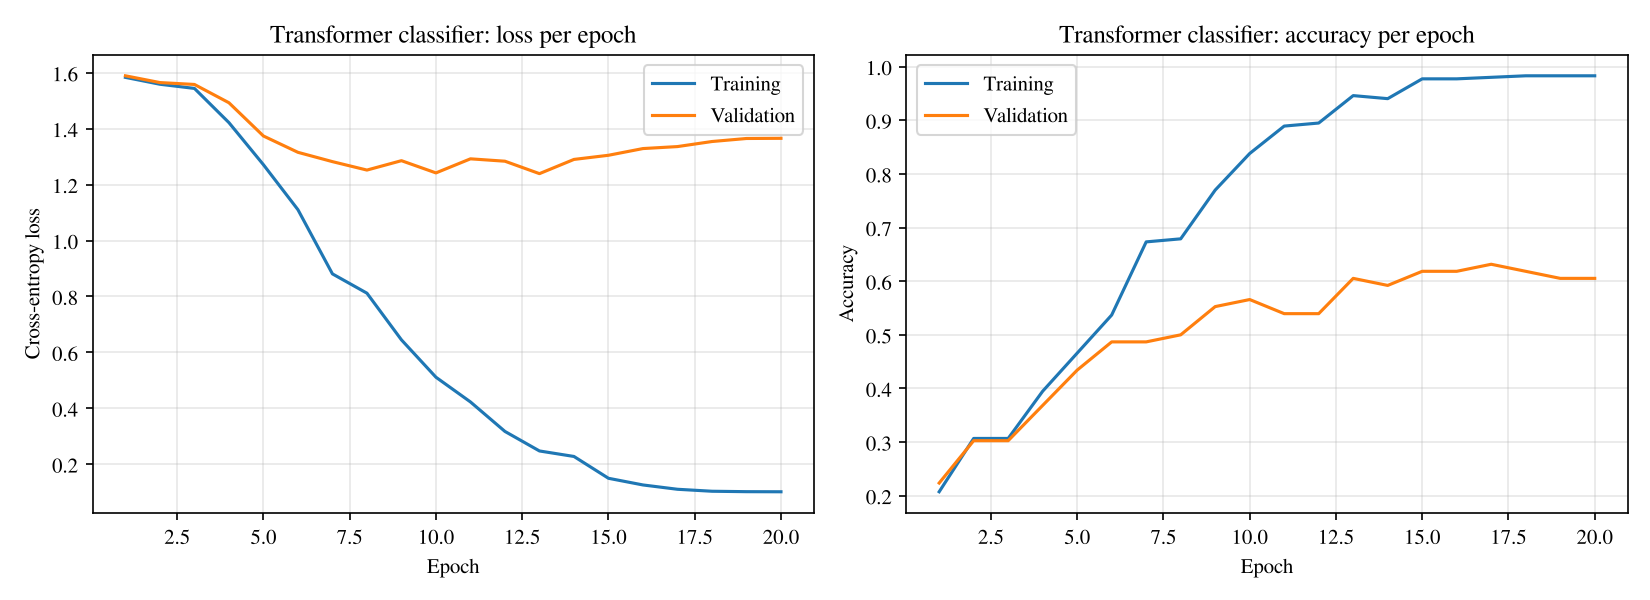

In [31]:
H = {k: load_json(f"p3_{k}.json") for k in ("transformer", "bilstm")}
print("Training: AdamW (lr 5e-4, weight decay 0.01), cosine LR schedule with 50 warm-up steps, 20 epochs, batch 16.\n")
print(pd.DataFrame({k: v for k, v in H["transformer"]["hist"].items()}).round(3).rename(columns=lambda c: c).assign(epoch=range(1, 21)).set_index("epoch").to_string())
show("transformer_cls_curves.png")

### 8. Evaluation

             test accuracy  macro-F1  best val acc  best epoch (val acc)
transformer         0.6842    0.6730        0.6316                  17.0
bilstm              0.5658    0.5616        0.5132                  14.0

Per-class F1 (Transformer): {'Politics': 0.5, 'Sports': 0.759, 'Economy': 0.667, 'International': 0.69, 'Health & Society': 0.75}
Confusion matrix rows = true, cols = predicted, order: ['Politics', 'Sports', 'Economy', 'International', 'Health & Society']
[[ 7  3  1  2  2]
 [ 2 11  0  1  1]
 [ 0  0  6  2  2]
 [ 1  0  0 10  2]
 [ 3  0  1  1 18]]


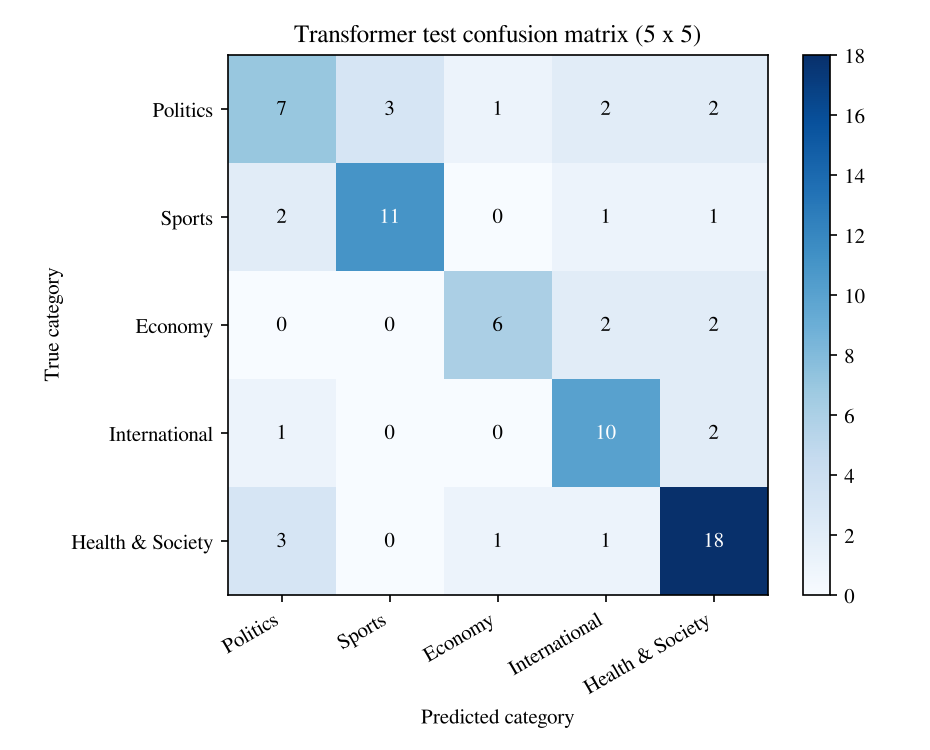

In [32]:
e3 = load_json("part3_eval.json")
print(pd.DataFrame({k: {"test accuracy": round(e3[k]["test_acc"], 4), "macro-F1": round(e3[k]["macro_f1"], 4), "best val acc": round(e3[k]["best_val_acc"], 4), "best epoch (val acc)": e3[k]["best_ep"]} for k in ("transformer", "bilstm")}).T.to_string())
print("\nPer-class F1 (Transformer):", {k: round(v, 3) for k, v in e3["transformer"]["per_class_f1"].items()})
print("Confusion matrix rows = true, cols = predicted, order:", part3.CATS); print(np.array(e3["transformer"]["cm"]))
show("transformer_cls_confusion.png")

Article 1: true = predicted = Sports (confidence 0.99); tokens with the highest [CLS] attention (final layer, head average): [['ایک', 0.0141], ['پینلٹی', 0.009], ['کیے', 0.0084], ['سکے', 0.008], ['کرنے', 0.0079], ['کیے', 0.0079]]


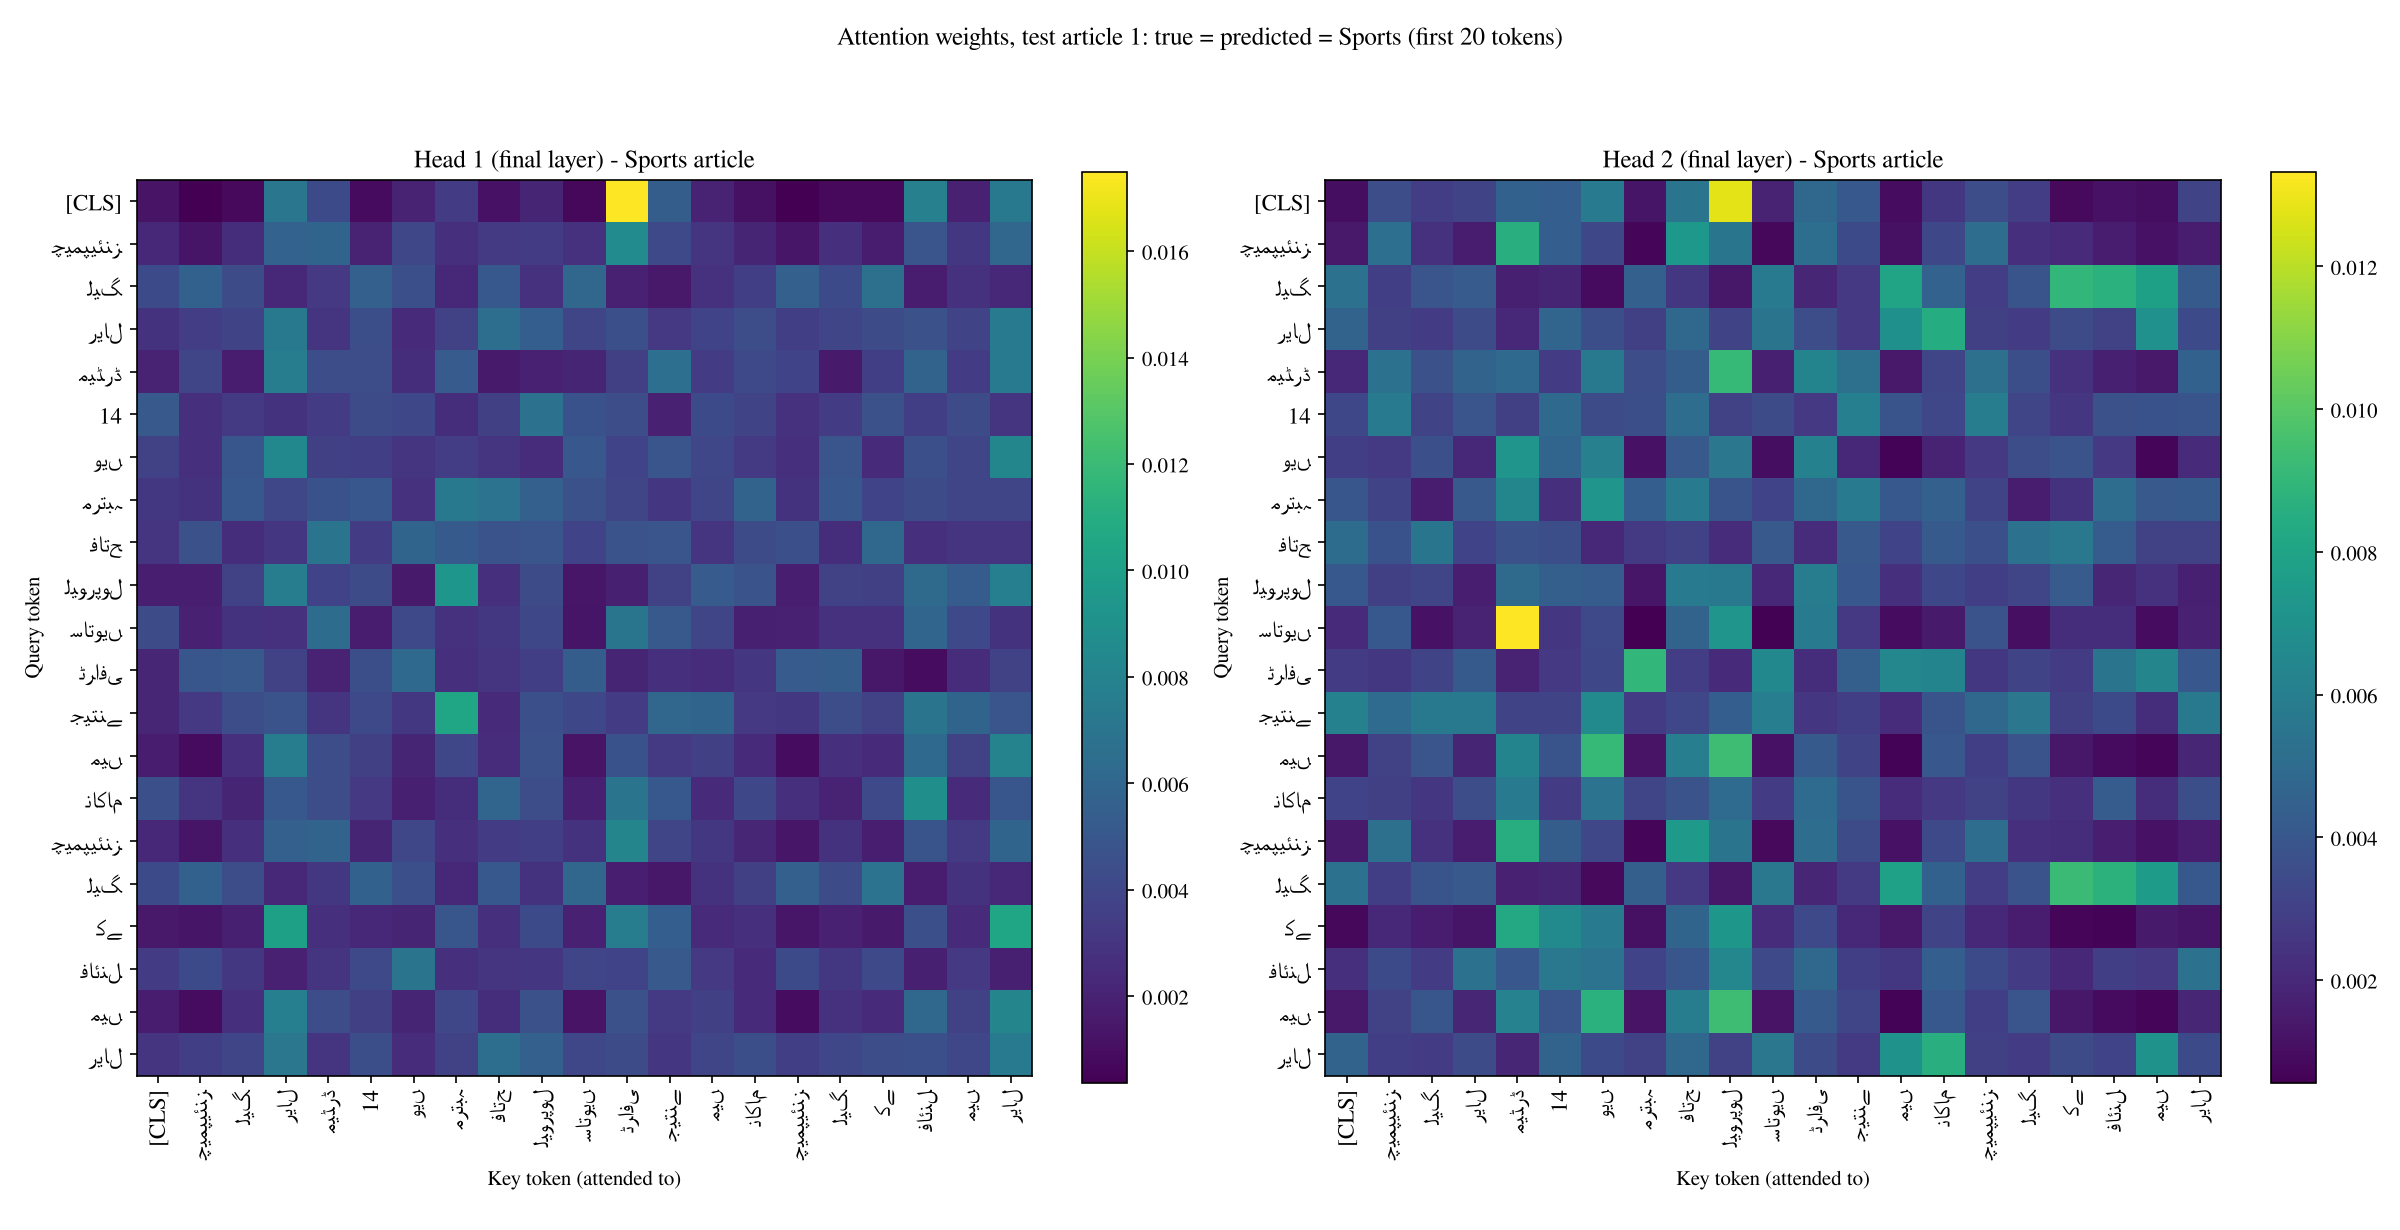

Article 2: true = predicted = International (confidence 0.96); tokens with the highest [CLS] attention (final layer, head average): [['جنگ', 0.1294], ['جنگ', 0.117], ['یورپی', 0.0202], ['یورپی', 0.0202], ['یورپی', 0.0201], ['یورپی', 0.0198]]


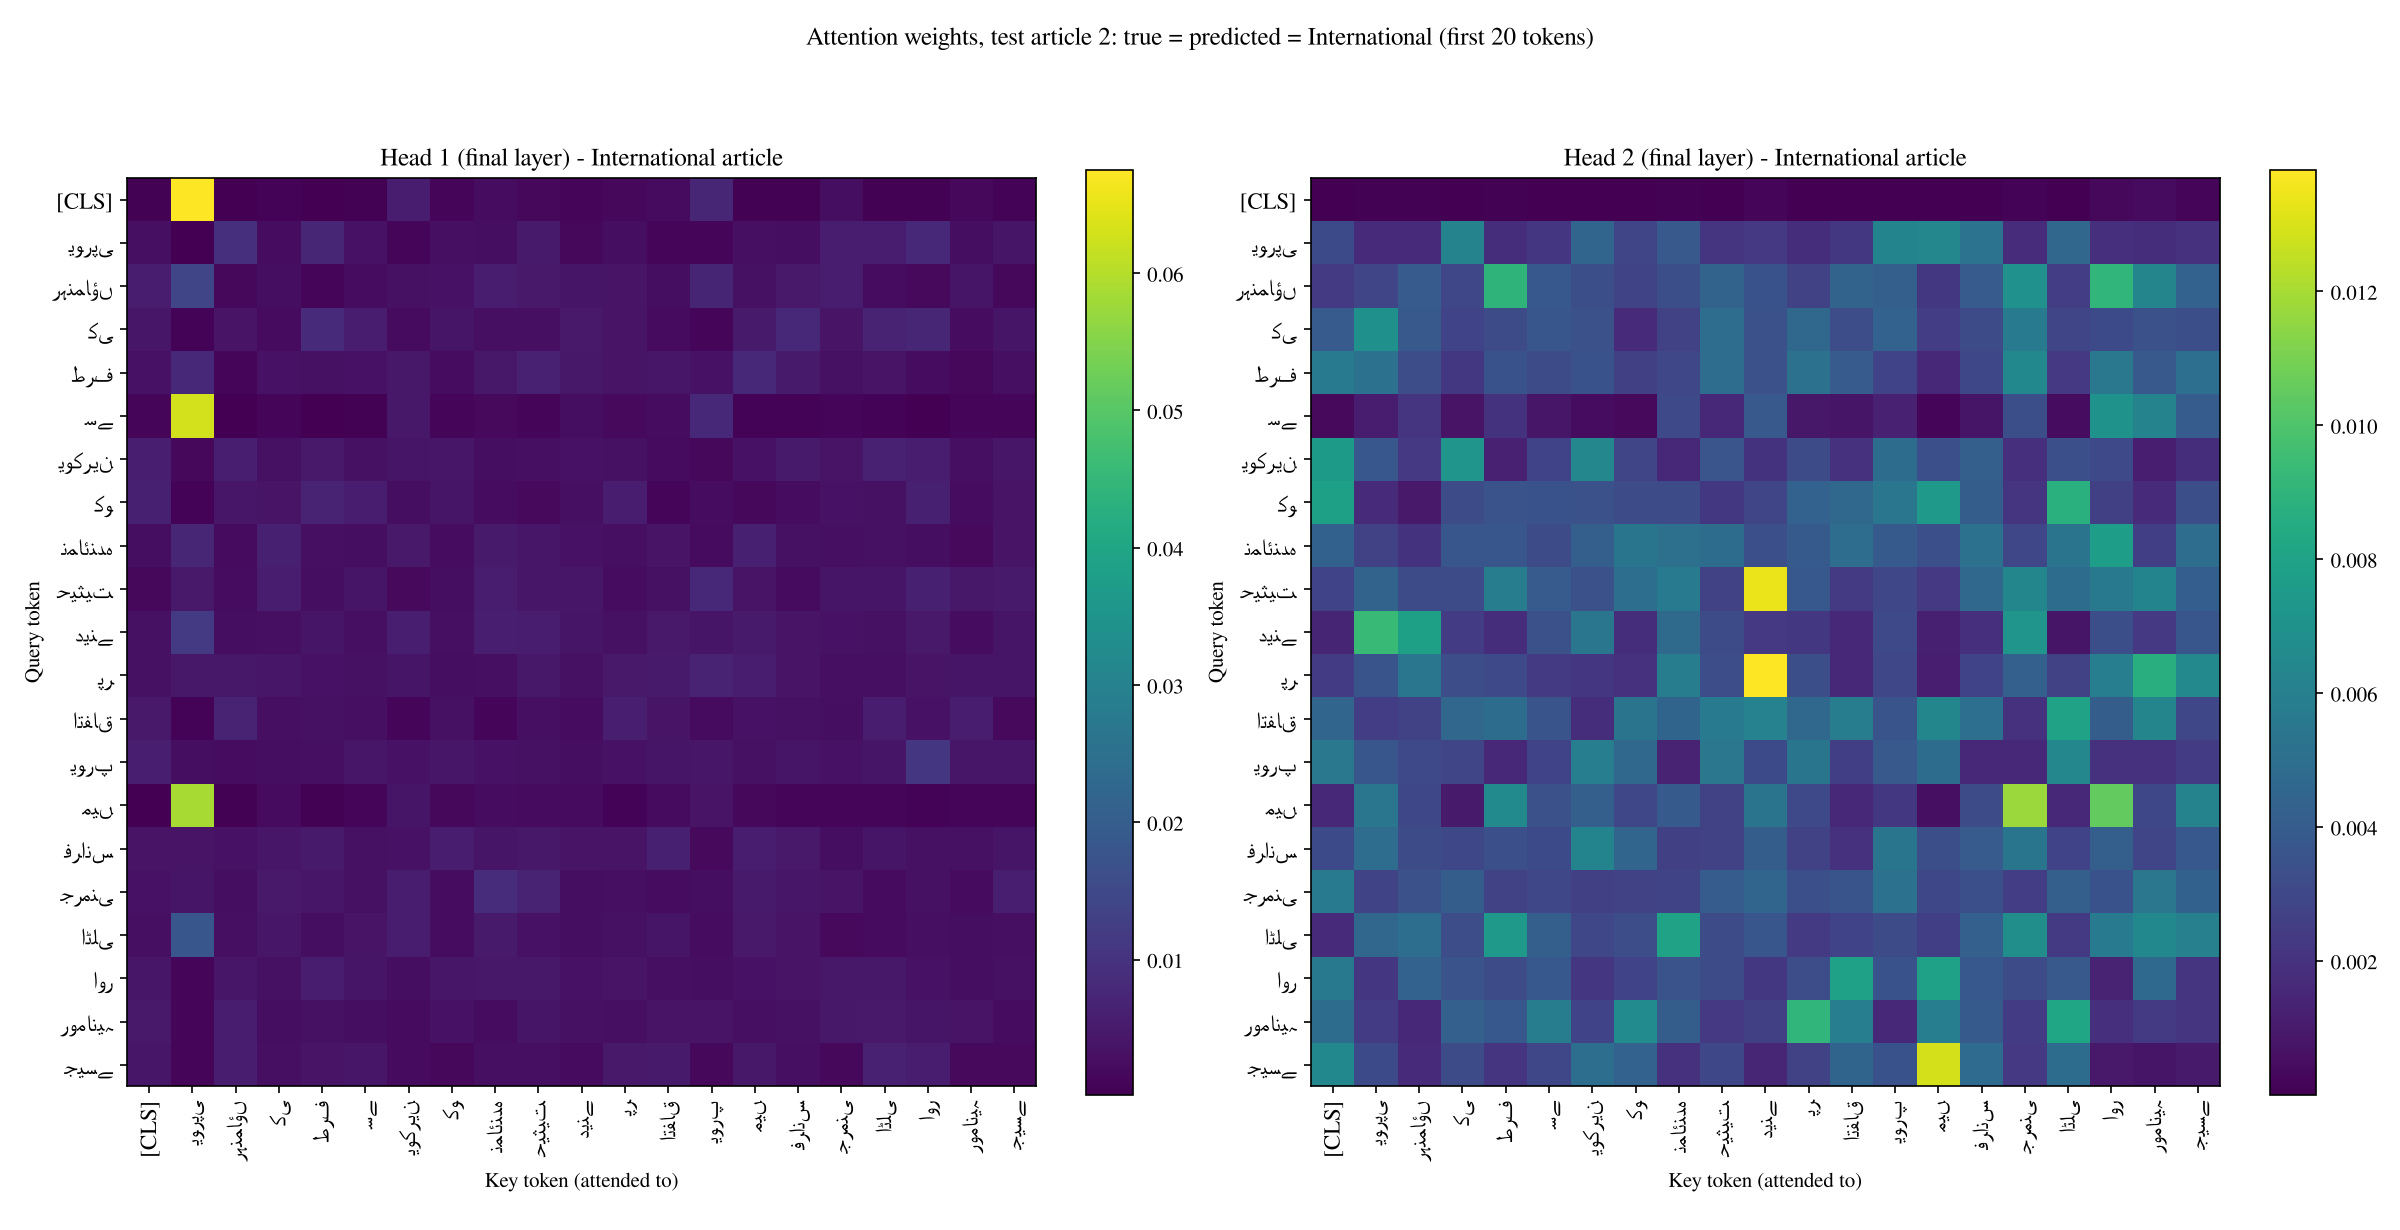

Article 3: true = predicted = Health & Society (confidence 0.98); tokens with the highest [CLS] attention (final layer, head average): [['ایک', 0.0169], ['واضح', 0.0162], ['ایک', 0.0155], ['آج', 0.0133], ['یقین', 0.013], ['موڑ', 0.013]]


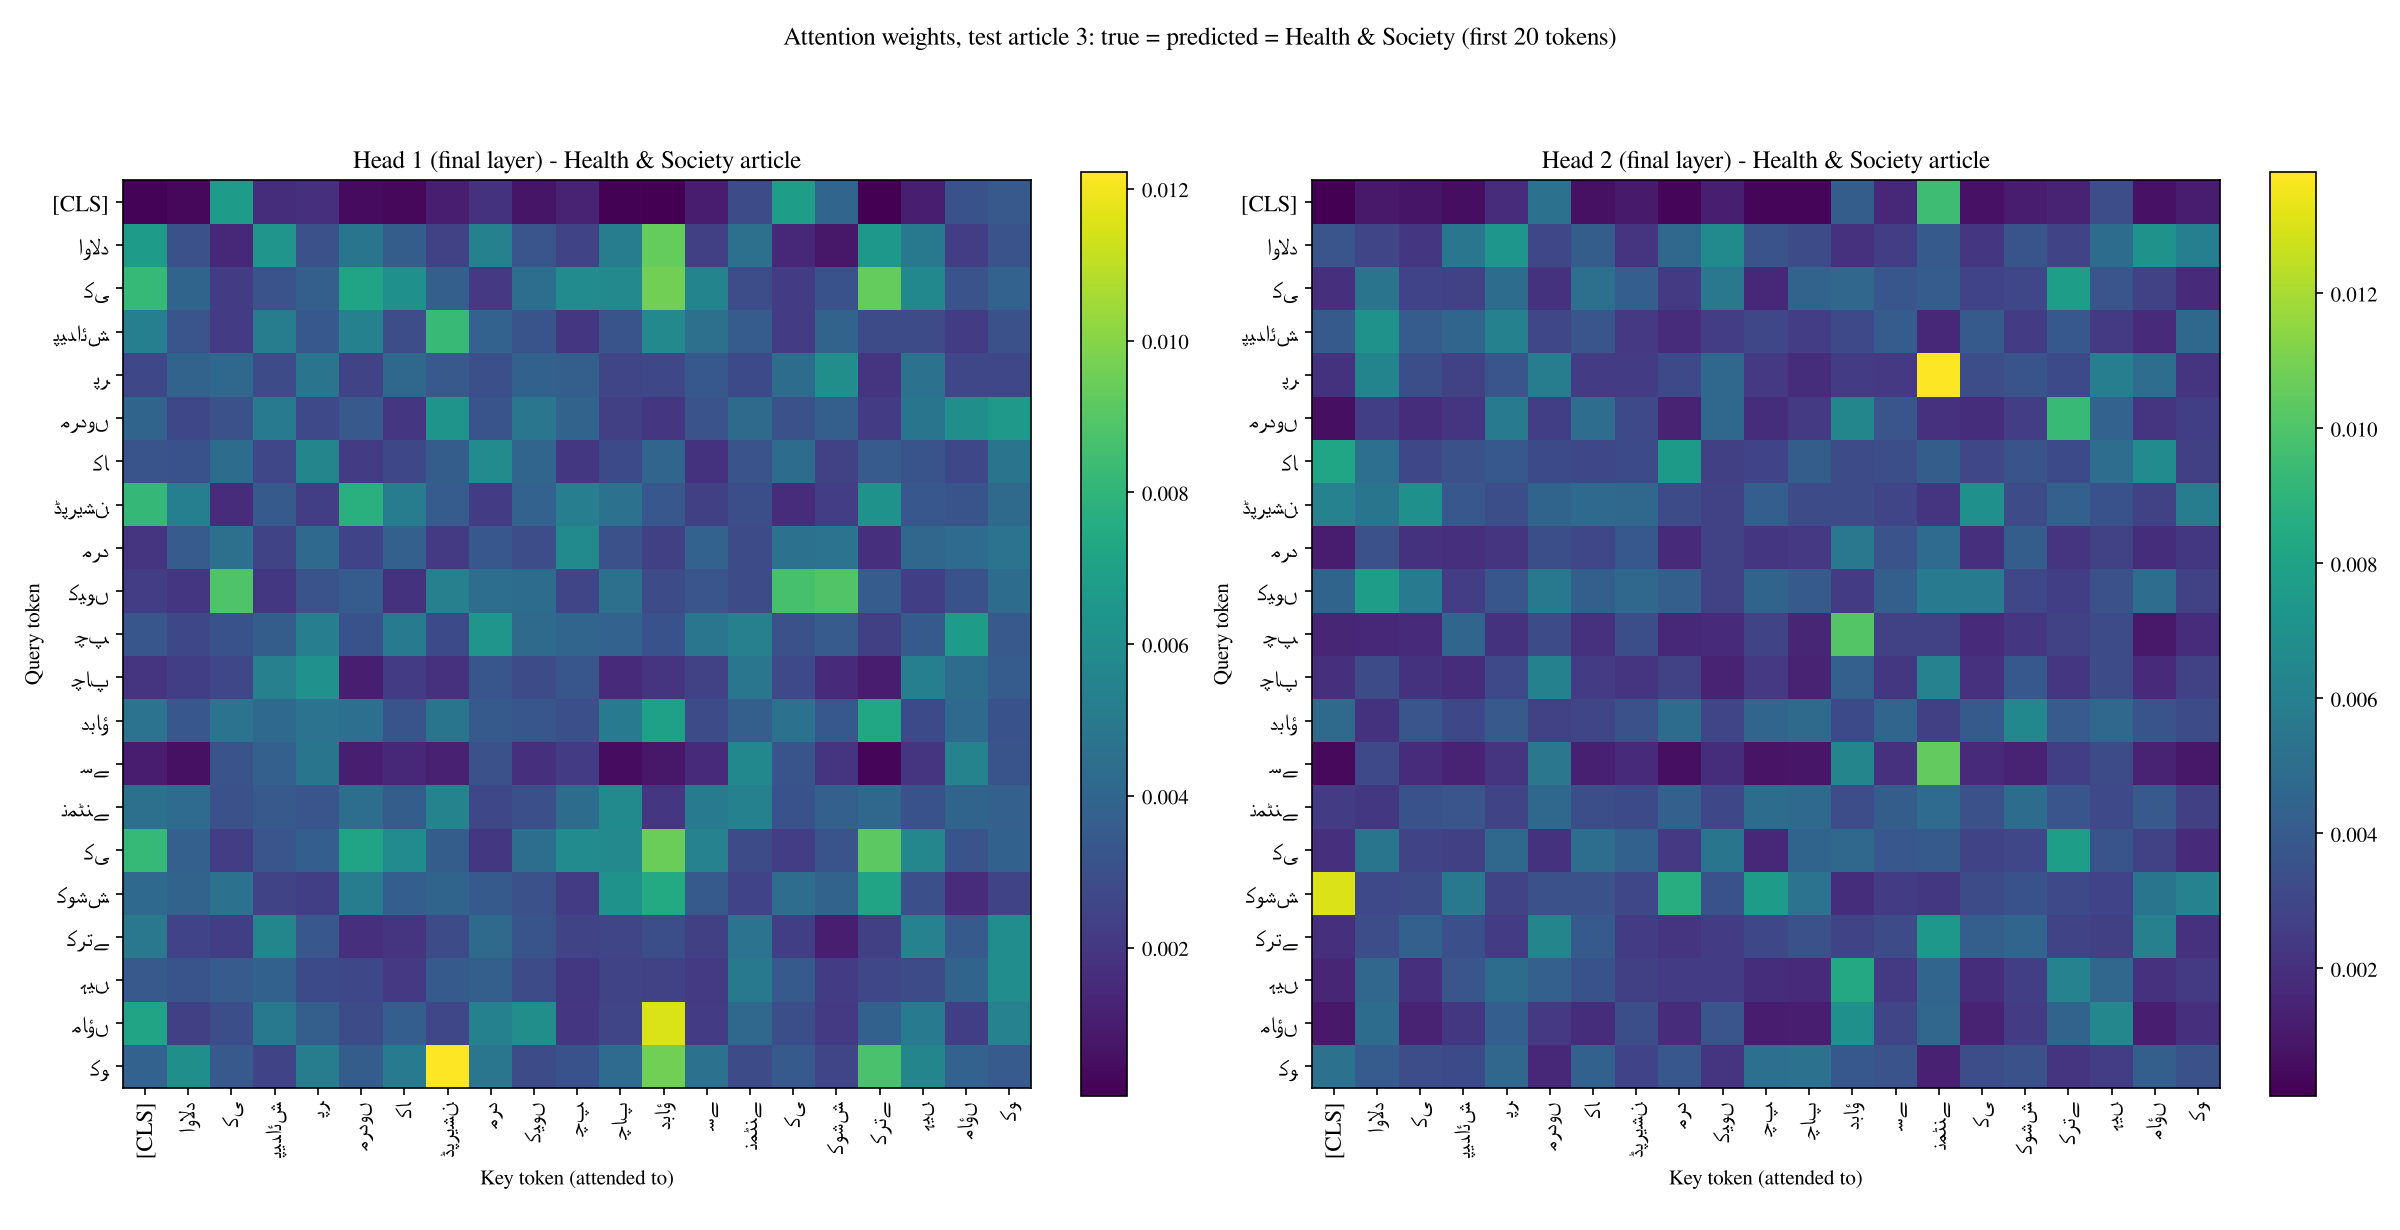

In [33]:
for i, ex in enumerate(e3["attention_examples"], 1):
    print(f"Article {i}: true = predicted = {ex['category']} (confidence {ex['conf']:.2f}); tokens with the highest [CLS] attention (final layer, head average):", ex["cls_top_tokens"][:6])
    show(f"attention_heatmap_{i}.png")

In [34]:
print("Most [CLS]-attended tokens per class (correctly classified test articles, final layer, mean over heads, tokens occurring >=3 times):")
for c, v in e3["cls_top_tokens_by_class"].items(): print(f"  {c:18s}", "  ".join(f"{a}({b})" for a, b in v[:6]))
print(f"\nShare of class keywords among each article's top-5 [CLS]-attended tokens: {e3['keyword_fraction_in_top5_cls_attention']:.3f}  (share of keywords among all tokens: {e3['keyword_fraction_baseline']:.3f})")

Most [CLS]-attended tokens per class (correctly classified test articles, final layer, mean over heads, tokens occurring >=3 times):
  Politics           پاکستانی(0.0862)  ویڈیو(0.0298)  سٹینفورڈ(0.0203)  کہا(0.0125)  ق(0.0099)  جبکہ(0.0096)
  Sports             کرکٹ(0.064)  سنچری(0.0168)  گیند(0.0071)  علی(0.007)  ملک(0.0066)  سکواش(0.0061)
  Economy            کام(0.0131)  کہا(0.0125)  بجٹ(0.0124)  مہنگائی(0.0118)  ایک(0.0088)  انہوں(0.008)
  International      جنگ(0.1414)  کام(0.0417)  پڑا(0.0219)  یورپی(0.0197)  گاؤں(0.0154)  اسے(0.0147)
  Health & Society   کام(0.0424)  رہنا(0.041)  لیورٹن(0.0402)  فلم(0.0293)  صرف(0.0258)  جنھیں(0.018)

Share of class keywords among each article's top-5 [CLS]-attended tokens: 0.158  (share of keywords among all tokens: 0.029)


### 8.2 BiLSTM vs Transformer

             test acc  macro-F1  epoch of min val loss  epoch of best val acc  epochs to 90% train acc  sec / epoch (1 CPU)  final train acc  final val acc
transformer     0.684     0.673                   13.0                   17.0                     13.0                 18.7            0.983          0.605
bilstm          0.566     0.562                    3.0                   14.0                      8.0                 26.8            1.000          0.434

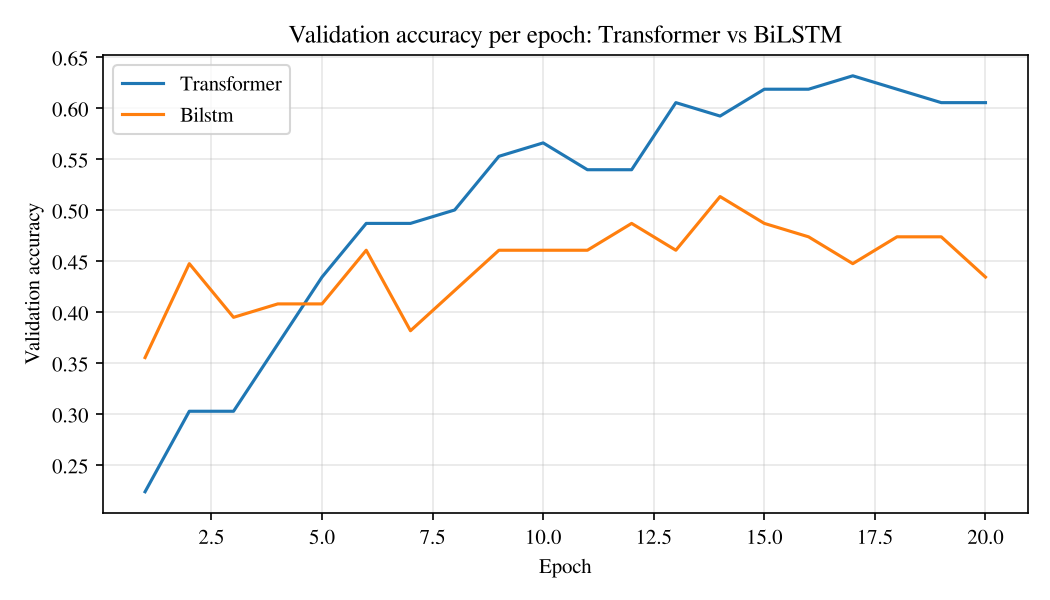

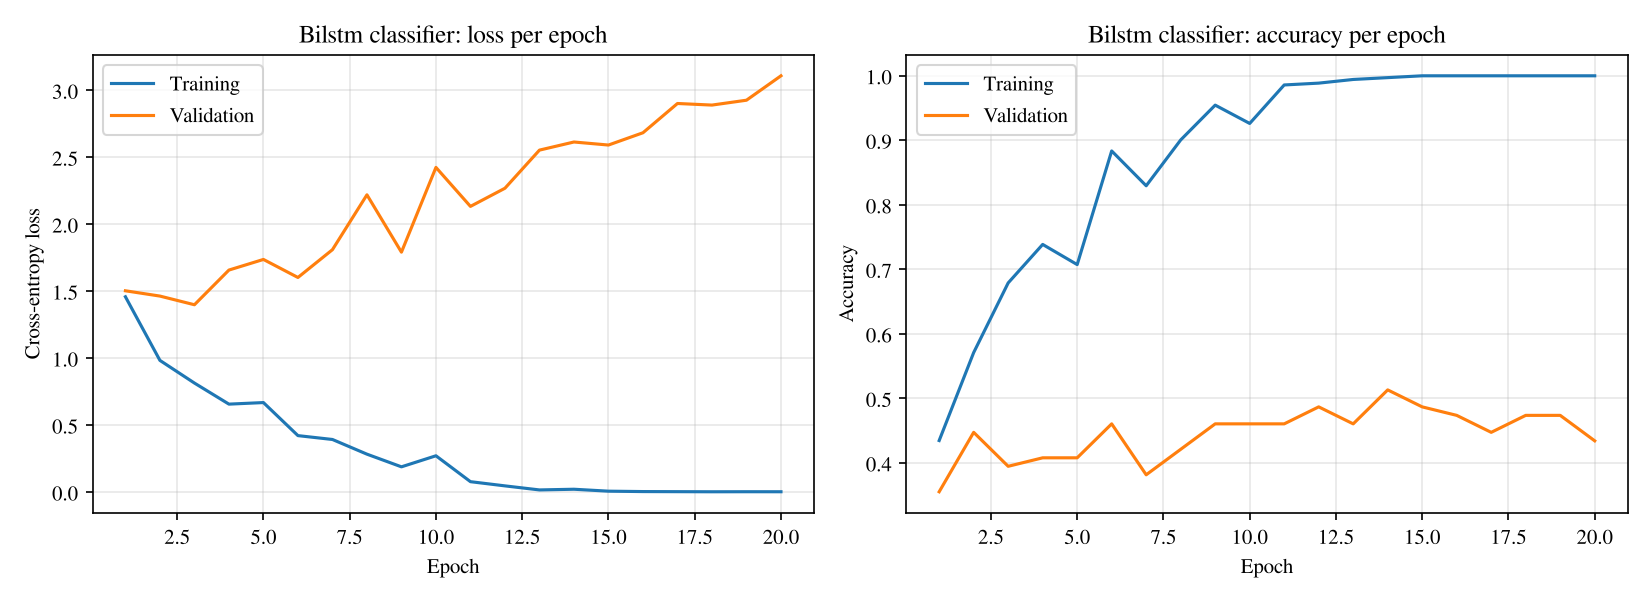

In [35]:
rows = {k: {"test acc": round(e3[k]["test_acc"], 3), "macro-F1": round(e3[k]["macro_f1"], 3), "epoch of min val loss": e3[k]["min_val_loss_epoch"], "epoch of best val acc": e3[k]["best_ep"],
            "epochs to 90% train acc": e3[k]["train_epochs_to_90pct_train_acc"], "sec / epoch (1 CPU)": round(e3[k]["mean_epoch_time"], 1), "final train acc": round(e3[k]["final_train_acc"], 3), "final val acc": round(e3[k]["final_val_acc"], 3)} for k in ("transformer", "bilstm")}
print(pd.DataFrame(rows).T.to_string()); show("cls_val_acc_comparison.png"); show("bilstm_cls_curves.png")

In [36]:
print("""BiLSTM vs Transformer (both trained from the same 352 training articles, 256 tokens)
1. The Transformer achieves the higher accuracy: 68.4% vs 56.6% on the 76 test articles, a gap of 11.8 points (macro-F1 0.673 vs 0.562); with one run and 76 test articles the uncertainty is roughly +-5 points.
2. In terms of fitting the training data the BiLSTM converges in fewer epochs (90% training accuracy after 8 epochs vs 13 for the Transformer, whose learning rate is still warming up for 50 steps).
3. That fast convergence is memorisation: the BiLSTM's validation loss is lowest at epoch 3 and then rises steeply while its training accuracy reaches 100%, whereas the Transformer's validation loss bottoms out at epoch 13.
4. The Transformer was also faster per epoch (18.7 s vs 26.8 s on one CPU), because self-attention processes all 257 positions in parallel while the two bidirectional LSTM layers must step through the sequence sequentially.
5. The attention heatmaps show that the [CLS] query concentrates its weight on a handful of tokens rather than spreading it uniformly.
6. These tokens are often topical: for sports articles the most attended tokens include کرکٹ and سنچری, for international news جنگ (war) receives by far the highest mean weight (0.14), and for economy بجٹ and مہنگائی.
7. Class keywords make up 15.8% of the top-5 [CLS]-attended tokens versus only 2.9% of all tokens, about five times more than chance, although function-like words such as کہا and کام are also attended.
8. Different heads specialise: in the heatmaps one head attends sharply to a few positions while another is more diffuse, giving the encoder several complementary views.
9. Both models over-fit badly (Transformer 98% training vs 61% validation accuracy; BiLSTM 100% vs 43%), which shows how little 352 articles are for models trained from scratch.
10. With only 200-300 articles neither from-scratch network is truly appropriate; our evidence favours the Transformer (better accuracy, smaller train/validation gap, faster) but only if it is kept small and heavily regularised.
11. The BiLSTM's advantage is its sequential inductive bias and fewer position-specific parameters, but its recurrent memory over 256 tokens did not help here.
12. For such a small dataset a TF-IDF + logistic-regression baseline, or a Transformer/BiLSTM initialised with pre-trained embeddings (not allowed in this assignment), would be safer.
13. Caveat: the 5-category labels come from keyword scoring (61 articles fell back to the BBC section), so label noise limits the achievable accuracy for both models.""")

BiLSTM vs Transformer (both trained from the same 352 training articles, 256 tokens)
1. The Transformer achieves the higher accuracy: 68.4% vs 56.6% on the 76 test articles, a gap of 11.8 points (macro-F1 0.673 vs 0.562); with one run and 76 test articles the uncertainty is roughly +-5 points.
2. In terms of fitting the training data the BiLSTM converges in fewer epochs (90% training accuracy after 8 epochs vs 13 for the Transformer, whose learning rate is still warming up for 50 steps).
3. That fast convergence is memorisation: the BiLSTM's validation loss is lowest at epoch 3 and then rises steeply while its training accuracy reaches 100%, whereas the Transformer's validation loss bottoms out at epoch 13.
4. The Transformer was also faster per epoch (18.7 s vs 26.8 s on one CPU), because self-attention processes all 257 positions in parallel while the two bidirectional LSTM layers must step through the sequence sequentially.
5. The attention heatmaps show that the [CLS] query concent

## GitHub submission & file manifest

In [37]:
print("Public repository (replace with the real URL before submitting):", "https://github.com/i258043-gif/i25-8043-NLP-Assignment2")
print("Folder structure mirrors the zip layout; see README.md for how to reproduce each part and make_commits.sh for the incremental commit history.\n")
for root in ("embeddings", "models", "data", "figures", "src"):
    print(root + "/:", ", ".join(sorted(os.listdir(P(root)))[:30]))

Public repository (replace with the real URL before submitting): https://github.com/i258043-gif/i25-8043-NLP-Assignment2
Folder structure mirrors the zip layout; see README.md for how to reproduce each part and make_commits.sh for the incremental commit history.

embeddings/: embeddings_w2v.npy, embeddings_w2v_d200.npy, embeddings_w2v_raw.npy, ppmi_matrix.npy, tfidf_matrix.npy, word2idx.json, word2idx_raw.json
models/: bilstm_cls.pt, bilstm_ner.pt, bilstm_pos.pt, skipgram_c3.pt, transformer_cls.pt
data/: cls_dataset.npz, cls_tokens.json, ner_test.conll, ner_train.conll, ner_val.conll, pos_test.conll, pos_train.conll, pos_val.conll, split_annotated.json
figures/: attention_heatmap_1.png, attention_heatmap_2.png, attention_heatmap_3.png, bilstm_cls_confusion.png, bilstm_cls_curves.png, cls_val_acc_comparison.png, ner_ft_loss_curves.png, pos_confusion_matrix.png, pos_ft_loss_curves.png, transformer_cls_confusion.png, transformer_cls_curves.png, tsne_ppmi_top200.png, w2v_loss_all_condition